# ShiftGuard: XGBoost risk model training

This notebook trains the ShiftGuard **employee wellbeing / workforce risk** model. The data is the existing synthetic training table in Supabase (`public.employee_risk_snapshot`).

| | |
|---|---|
| **Target** | `risk_outcome_within_30d` (binary) |
| **Model** | `xgboost.XGBClassifier` |
| **Explainability** | SHAP (TreeSHAP) |
| **Artifacts** | `model_artifacts/model.json`, `feature_names.json`, `model_config.json`, `risk_inference.py` |

> **Prototype disclaimer.** The training data is **synthetic** and exists only to demonstrate the ML architecture. Nothing in this notebook shows clinical or real-world predictive validity. The risk bands are prototype thresholds, not clinically validated ones.

**How to run**

1. Set the environment variables `SUPABASE_URL` and `SUPABASE_KEY`, either in your shell or in a `.env` file next to this notebook. Never hard-code them here.
2. `pip install pandas numpy xgboost shap scikit-learn matplotlib seaborn supabase python-dotenv`
3. Run all cells. The notebook **only reads** from Supabase. It never writes predictions back.

To run offline from a CSV export, set `SHIFTGUARD_DATA_SOURCE=csv` and `SHIFTGUARD_SNAPSHOT_CSV=<path>`. You can also set `SHIFTGUARD_EMPLOYEE_CSV=<path>`.

## 1. Imports and configuration

All tunable values live here: validation expectations, split sizes, XGBoost parameters, risk bands and artifact paths. Nothing further down should hard-code them.

In [1]:
import os
import sys
import json
import importlib
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost as xgb
import shap
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
    accuracy_score, brier_score_loss, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | xgboost {xgb.__version__} | "
      f"shap {shap.__version__} | scikit-learn {sklearn.__version__}")

python 3.14.10 | pandas 3.1.1 | xgboost 3.4.1 | shap 0.54.1 | scikit-learn 1.9.1


In [2]:
# ---------------------------------------------------------------- data source
RANDOM_STATE = 42
DATA_SOURCE = os.environ.get("SHIFTGUARD_DATA_SOURCE", "supabase").lower()   # "supabase" | "csv"
SNAPSHOT_CSV_PATH = os.environ.get("SHIFTGUARD_SNAPSHOT_CSV", "employee_risk_snapshot.csv")
EMPLOYEE_CSV_PATH = os.environ.get("SHIFTGUARD_EMPLOYEE_CSV", "")              # optional
SNAPSHOT_TABLE = "employee_risk_snapshot"
EMPLOYEE_TABLE = "employee"
# Deliberately below PostgREST's usual 1,000-row cap so pagination is always exercised.
PAGE_SIZE = 500

# ------------------------------------------------------- expected data shape
EXPECTED_ROWS = 1120
EXPECTED_EMPLOYEES = 20
EXPECTED_SNAPSHOTS_PER_EMPLOYEE = 56
EXPECTED_MIN_DATE = pd.Timestamp("2026-09-23")
EXPECTED_MAX_DATE = pd.Timestamp("2026-11-17")
EXPECTED_MANAGER_ONLY_EMPLOYEES = 3
STRICT_VALIDATION = True          # stop before training if any validation check fails

# ------------------------------------------------------------- column roles
# Identifier / metadata columns: NEVER model features.
ID_METADATA_COLUMNS = [
    "risk_snapshot_id", "employee_id", "snapshot_date",
    "is_training_record", "created_at", "updated_at",
]
TARGET = "risk_outcome_within_30d"
# risk_label is derived from the same underlying risk as the target, so using it as a feature
# would leak the answer. The target is obviously excluded too.
LEAKAGE_COLUMNS = ["risk_label", TARGET]

MATERNITY_FEATURES = [
    "days_since_maternity_return",
    "return_schedule_variance_hours_30d",
    "overtime_hours_since_maternity_return",
    "maternity_adjustments_fulfilment_ratio",
    "nursing_or_recovery_breaks_missed_30d",
]

# Exact feature order. This order is saved to feature_names.json and FastAPI MUST use it.
FEATURES = [
    "contracted_hours_30d",
    "actual_hours_worked_30d",
    "overtime_hours_30d",
    "overtime_ratio_30d",
    "night_shifts_30d",
    "long_shifts_30d",
    "max_consecutive_work_days",
    "max_consecutive_night_shifts",
    "minimum_rest_hours_between_shifts",
    "short_notice_roster_changes_30d",
    "missed_breaks_30d",
    "unplanned_absence_days_90d",
    "unplanned_absence_episodes_90d",
    "late_arrivals_30d",
    "days_since_last_meaningful_leave",
    "cancelled_or_rejected_leave_90d",
    "understaffed_shift_ratio_30d",
    "average_patient_load_ratio_30d",
    "redeployments_90d",
    "wellbeing_score",
    *MATERNITY_FEATURES,
    "end_of_life_care_7d",
]

# ------------------------------------------------------------ modelling
N_TEST_EMPLOYEES = 4              # 16 employees train / 4 unseen employees test
# The single test split must be representative: its positive rate must be at least this share of
# the overall rate. Without this rule a random draw once gave a test set with only 3 positive rows.
MIN_TEST_POSITIVE_SHARE = 0.5
N_CV_FOLDS = 5                    # 5 group folds x 4 employees each

# Probability calibration used for risk bands and the API:
#   "platt" -> logistic recalibration fitted on grouped out-of-fold predictions (recommended;
#              honest because every prediction comes from a model that never saw that employee)
#   "prior" -> simple correction for scale_pos_weight only (tends to under-predict on new employees)
CALIBRATION_METHOD = "platt"
TARGET_RECALL_FOR_ALERTS = 0.80   # used only to SUGGEST an alert threshold (section 17d)
# The classification threshold applies to the RAW (class-weighted) model score. With
# scale_pos_weight = w, raw >= 0.5 is the same as calibrated probability >= 1/(1+w), which is
# roughly the base rate. That makes it a recall-oriented "worth a look" cut-off.
CLASSIFICATION_THRESHOLD = 0.5

XGB_PARAMS = dict(
    n_estimators=300,
    max_depth=3,                  # shallow trees: little data, and easier to explain
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,           # stops tiny leaves fitting one employee's quirks
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    # missing=np.nan is the default: NaN is routed down a learned "missing" branch at every split.
)

# --------------------------------------------- prototype risk bands (configurable)
# These bands apply to the CALIBRATED probability (see section 15).
# They are prototype application thresholds, NOT clinically validated thresholds.
RISK_BANDS = [
    {"band": "LOW",      "min_probability": 0.00},
    {"band": "MEDIUM",   "min_probability": 0.30},
    {"band": "HIGH",     "min_probability": 0.60},
    {"band": "CRITICAL", "min_probability": 0.80},
]
TOP_K_FACTORS = 5

# ------------------------------------------------------------ artifacts
ARTIFACT_DIR = Path("model_artifacts")   # section 27 writes risk_inference.py to this literal path
MODEL_PATH = ARTIFACT_DIR / "model.json"
FEATURE_NAMES_PATH = ARTIFACT_DIR / "feature_names.json"
MODEL_CONFIG_PATH = ARTIFACT_DIR / "model_config.json"

assert len(FEATURES) == 26 and len(set(FEATURES)) == 26, "Feature list must contain 26 unique columns"
assert not set(FEATURES) & set(ID_METADATA_COLUMNS + LEAKAGE_COLUMNS), "ID/leakage column in FEATURES"
print(f"Data source: {DATA_SOURCE} | {len(FEATURES)} features | target: {TARGET}")

Data source: supabase | 26 features | target: risk_outcome_within_30d


## 2. Supabase connection (or CSV fallback)

Credentials come **only** from environment variables (`SUPABASE_URL`, `SUPABASE_KEY`). If `python-dotenv` is installed, a local `.env` file is loaded too. Keep `.env` out of git.

Which key to use:
- The **anon key** works only if Row Level Security lets it `SELECT` from `employee_risk_snapshot` and `employee`. If RLS blocks it, the fetch quietly returns 0 rows, and the validation checks below will catch that.
- A **service-role key** bypasses RLS. Use it only on your own machine for training, and never ship it to the frontend.

**Pagination.** PostgREST caps the rows returned per request (often at 1,000). `fetch_all_rows` therefore:
1. asks the server for the exact row count first;
2. pages through with `.range(start, end)`, ordered by a unique key so pages are stable;
3. advances by the number of rows *actually returned*, so a smaller server cap can't cause skipped rows;
4. raises an error if the number of rows fetched differs from the server's count. It never silently trains on only the first page.

In [3]:
def get_supabase_client():
    """Create a Supabase client from environment variables (no hard-coded credentials)."""
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass
    from supabase import create_client

    url = os.environ.get("SUPABASE_URL")
    key = os.environ.get("SUPABASE_KEY")
    if not url or not key:
        raise RuntimeError(
            "SUPABASE_URL / SUPABASE_KEY are not set. Export them (or put them in a .env file), "
            "or set SHIFTGUARD_DATA_SOURCE=csv to load from a CSV export instead."
        )
    return create_client(url, key)


def fetch_all_rows(client, table, filters=None, order_by=(), page_size=PAGE_SIZE):
    """Fetch every row of `table` that matches `filters`, using explicit range pagination.

    Returns (DataFrame, server_count). Raises if the fetched count doesn't match the server's count.
    """
    filters = filters or {}

    def build(count=None):
        q = client.table(table).select("*", count=count) if count else client.table(table).select("*")
        for col, val in filters.items():
            q = q.eq(col, val)
        return q

    server_count = build(count="exact").limit(1).execute().count
    print(f"{table}: server reports {server_count} matching rows (filters={filters})")

    rows, start = [], 0
    while True:
        q = build()
        for col in order_by:
            q = q.order(col)
        page = q.range(start, start + page_size - 1).execute().data or []
        if not page:
            break
        rows.extend(page)
        print(f"  fetched rows {start}..{start + len(page) - 1} ({len(page)} rows)")
        start += len(page)                     # advance by what we actually got
        if server_count is not None and len(rows) >= server_count:
            break
        if server_count is None and len(page) < page_size:
            break

    if server_count is not None and len(rows) != server_count:
        raise RuntimeError(f"{table}: fetched {len(rows)} rows but the server reports {server_count}. "
                           "Pagination problem; refusing to continue.")
    return pd.DataFrame(rows), server_count

## 3. Load `employee_risk_snapshot`

Only rows with `is_training_record = true` are used. Supabase returns JSON, where Postgres `numeric` columns can arrive as strings. Every feature is therefore converted to a number explicitly. If a non-null value can't be parsed, the notebook raises an error rather than quietly turning it into NaN.

In [4]:
if DATA_SOURCE == "supabase":
    supabase = get_supabase_client()
    raw_df, server_row_count = fetch_all_rows(
        supabase, SNAPSHOT_TABLE,
        filters={"is_training_record": True},
        order_by=("employee_id", "snapshot_date", "risk_snapshot_id"),
    )
    try:
        employee_df, _ = fetch_all_rows(supabase, EMPLOYEE_TABLE, order_by=("employee_id",))
    except Exception as exc:                       # employee table is optional (display only)
        print(f"Could not load {EMPLOYEE_TABLE} (display only, continuing): {exc}")
        employee_df = None
elif DATA_SOURCE == "csv":
    raw_df = pd.read_csv(SNAPSHOT_CSV_PATH)
    server_row_count = None
    employee_df = pd.read_csv(EMPLOYEE_CSV_PATH) if EMPLOYEE_CSV_PATH else None
    print(f"Loaded {len(raw_df)} rows from {SNAPSHOT_CSV_PATH}")
else:
    raise ValueError(f"Unknown DATA_SOURCE {DATA_SOURCE!r}")

print(f"Raw rows retrieved: {len(raw_df)} | columns: {raw_df.shape[1]}")

employee_risk_snapshot: server reports 1120 matching rows (filters={'is_training_record': True})
  fetched rows 0..499 (500 rows)
  fetched rows 500..999 (500 rows)
  fetched rows 1000..1119 (120 rows)
employee: server reports 23 matching rows (filters={})
  fetched rows 0..22 (23 rows)
Raw rows retrieved: 1120 | columns: 34


In [5]:
def to_bool(series):
    """Parse booleans that may arrive as bool, 'true'/'false', 't'/'f' or 1/0. Unknown -> NaN."""
    mapping = {"true": True, "t": True, "1": True, "yes": True,
               "false": False, "f": False, "0": False, "no": False}
    def parse(v):
        if isinstance(v, (bool, np.bool_)):
            return bool(v)
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        return mapping.get(str(v).strip().lower(), np.nan)
    return series.map(parse)


required_columns = ["employee_id", "snapshot_date", "is_training_record", TARGET, *FEATURES]
missing_columns = [c for c in required_columns if c not in raw_df.columns]
if missing_columns:
    raise KeyError(f"Missing required columns in {SNAPSHOT_TABLE}: {missing_columns}")

df = raw_df.copy()
df["employee_id"] = df["employee_id"].astype(str)
df["snapshot_date"] = pd.to_datetime(df["snapshot_date"]).dt.tz_localize(None).dt.normalize()
df["is_training_record"] = to_bool(df["is_training_record"])
df[TARGET] = to_bool(df[TARGET])

for col in FEATURES:
    nulls_before = df[col].isna().sum()
    df[col] = pd.to_numeric(df[col], errors="coerce").astype(float)
    if df[col].isna().sum() != nulls_before:
        raise ValueError(f"{col}: {df[col].isna().sum() - nulls_before} non-null values could not be parsed as numbers")

# Apply the training filter again locally (a no-op for Supabase; needed for CSV exports).
n_before = len(df)
df = df[df["is_training_record"] == True].copy()            # noqa: E712
print(f"Rows dropped by is_training_record filter: {n_before - len(df)}")

df = df.sort_values(["employee_id", "snapshot_date"]).reset_index(drop=True)
df.head()

Rows dropped by is_training_record filter: 0


,risk_snapshot_id,employee_id,snapshot_date,contracted_hours_30d,actual_hours_worked_30d,overtime_hours_30d,overtime_ratio_30d,night_shifts_30d,long_shifts_30d,max_consecutive_work_days,max_consecutive_night_shifts,minimum_rest_hours_between_shifts,short_notice_roster_changes_30d,missed_breaks_30d,unplanned_absence_days_90d,unplanned_absence_episodes_90d,late_arrivals_30d,days_since_last_meaningful_leave,cancelled_or_rejected_leave_90d,understaffed_shift_ratio_30d,average_patient_load_ratio_30d,redeployments_90d,wellbeing_score,days_since_maternity_return,return_schedule_variance_hours_30d,overtime_hours_since_maternity_return,maternity_adjustments_fulfilment_ratio,nursing_or_recovery_breaks_missed_30d,risk_label,risk_outcome_within_30d,is_training_record,created_at,updated_at,end_of_life_care_7d
0,bfe5cecc-43d1-57e2-a277-296c615f243e,10000000-0000-0000-0000-000000000001,2026-09-23,160.0,154.74,0.0,0.0,2.0,0.0,4.0,1.0,13.16,0.0,0.0,0.0,0.0,0.0,28.0,0.0,0.0876,0.94,0.0,3.35,NaN,NaN,NaN,NaN,NaN,LOW,False,True,2026-11-17T10:26:07.08384+00:00,2026-11-17T10:26:07.08384+00:00,0.0
1,1732d731-101f-5bed-a1f4-867fce99bfb2,10000000-0000-0000-0000-000000000001,2026-09-24,160.0,155.40,0.0,0.0,2.0,0.0,4.0,1.0,13.13,0.0,0.0,0.0,0.0,0.0,28.0,0.0,0.0894,0.94,0.0,NaN,NaN,NaN,NaN,NaN,NaN,MEDIUM,False,True,2026-11-17T10:26:07.08384+00:00,2026-11-17T10:26:07.08384+00:00,1.0
2,bb827bda-56a3-5f44-93b2-5aa39fffd3ae,10000000-0000-0000-0000-000000000001,2026-09-25,160.0,156.03,0.0,0.0,2.0,0.0,4.0,2.0,13.11,0.0,0.0,0.0,0.0,0.0,29.0,0.0,0.0912,0.95,0.0,3.37,NaN,NaN,NaN,NaN,NaN,LOW,False,True,2026-11-17T10:26:07.08384+00:00,2026-11-17T10:26:07.08384+00:00,1.0
3,15cd21c9-7999-5d8c-8171-7db49ff79505,10000000-0000-0000-0000-000000000001,2026-09-26,160.0,156.62,0.0,0.0,2.0,0.0,4.0,2.0,13.08,0.0,0.0,0.0,0.0,0.0,29.0,0.0,0.0929,0.95,0.0,3.38,NaN,NaN,NaN,NaN,NaN,LOW,False,True,2026-11-17T10:26:07.08384+00:00,2026-11-17T10:26:07.08384+00:00,1.0
4,2f776867-3995-55ef-a175-e95bd2f7a9a6,10000000-0000-0000-0000-000000000001,2026-09-27,160.0,157.15,0.0,0.0,2.0,0.0,4.0,2.0,13.06,0.0,0.0,0.0,0.0,0.0,29.0,0.0,0.0945,0.95,0.0,3.39,NaN,NaN,NaN,NaN,NaN,LOW,False,True,2026-11-17T10:26:07.08384+00:00,2026-11-17T10:26:07.08384+00:00,1.0


## 4. Basic dataset validation

Each check is recorded as PASS or FAIL and shown in a table. A gate cell at the end of section 8 stops the notebook before training if any check failed.

In [6]:
VALIDATION_RESULTS = []

def check(name, expected, actual, passed):
    VALIDATION_RESULTS.append({"check": name, "expected": str(expected), "actual": str(actual),
                               "status": "PASS" if passed else "FAIL"})

def show_checks(start=0):
    display(pd.DataFrame(VALIDATION_RESULTS[start:]).style.map(
        lambda v: "color: green" if v == "PASS" else ("color: red; font-weight: bold" if v == "FAIL" else ""),
        subset=["status"]))

_start = len(VALIDATION_RESULTS)
check("Total training rows", EXPECTED_ROWS, len(df), len(df) == EXPECTED_ROWS)
if server_row_count is not None:
    check("Fetched rows == server count", server_row_count, len(raw_df), len(raw_df) == server_row_count)
if "risk_snapshot_id" in df.columns:
    n_dup_ids = df["risk_snapshot_id"].duplicated().sum()
    check("Unique risk_snapshot_id", 0, f"{n_dup_ids} duplicates", n_dup_ids == 0)
n_dup_keys = df.duplicated(["employee_id", "snapshot_date"]).sum()
check("Unique (employee_id, snapshot_date)", 0, f"{n_dup_keys} duplicates", n_dup_keys == 0)
n_null_target = df[TARGET].isna().sum()
check(f"{TARGET} has no NULLs", 0, n_null_target, n_null_target == 0)
check(f"{TARGET} has both classes", "{False, True}", set(df[TARGET].dropna().unique()),
      set(df[TARGET].dropna().unique()) == {False, True})
show_checks(_start)

,check,expected,actual,status
0,Total training rows,1120,1120,PASS
1,Fetched rows == server count,1120,1120,PASS
2,Unique risk_snapshot_id,0,0 duplicates,PASS
3,"Unique (employee_id, snapshot_date)",0,0 duplicates,PASS
4,risk_outcome_within_30d has no NULLs,0,0,PASS
5,risk_outcome_within_30d has both classes,"{False, True}","{np.False_, np.True_}",PASS


## 5. Verify 20 unique operational employees

The 3 manager-only employees should exist in `employee` but have **no** snapshot rows. Employee master-data fields (name, email, role, manager, buddy) are used only for display and are **never** model features.

In [7]:
_start = len(VALIDATION_RESULTS)
snapshot_employees = set(df["employee_id"].unique())
check("Unique operational employees", EXPECTED_EMPLOYEES, len(snapshot_employees),
      len(snapshot_employees) == EXPECTED_EMPLOYEES)

if employee_df is not None and "employee_id" in employee_df.columns:
    employee_df["employee_id"] = employee_df["employee_id"].astype(str)
    all_employees = set(employee_df["employee_id"])
    not_in_master = snapshot_employees - all_employees
    no_snapshots = all_employees - snapshot_employees
    check("Snapshot employees exist in employee table", 0, f"{len(not_in_master)} missing", not not_in_master)
    check("Employees without snapshots (manager-only)", EXPECTED_MANAGER_ONLY_EMPLOYEES, len(no_snapshots),
          len(no_snapshots) == EXPECTED_MANAGER_ONLY_EMPLOYEES)
    display(employee_df[employee_df["employee_id"].isin(no_snapshots)].drop(columns=["email"], errors="ignore"))
else:
    print("employee table not loaded; skipping master-data checks (display names will fall back to IDs)")
show_checks(_start)


def employee_label(emp_id):
    """Human-friendly label for charts and demo output (display only)."""
    if employee_df is not None:
        row = employee_df.loc[employee_df["employee_id"] == str(emp_id)]
        if len(row) and {"first_name", "last_name"} <= set(row.columns):
            return f"{row.iloc[0]['first_name']} {row.iloc[0]['last_name']} ({emp_id})"
    return str(emp_id)

,employee_id,employee_number,first_name,last_name,job_role,department,location,manager_employee_id,buddy_employee_id,employment_type,contracted_weekly_hours,hire_date,maternity_return_date,is_active,created_at,updated_at
20,10000000-0000-0000-0000-000000000021,SG021,Maya,Kapoor,Care Manager,Care Services,Demo Care Home,NaN,NaN,FULL_TIME,40.0,2017-03-15,NaN,True,2026-11-17T10:34:00.330689+00:00,2026-11-17T10:34:00.330689+00:00
21,10000000-0000-0000-0000-000000000022,SG022,Rakesh,Mehta,Care Manager,Care Services,Demo Care Home,NaN,NaN,FULL_TIME,40.0,2016-08-10,NaN,True,2026-11-17T10:34:00.330689+00:00,2026-11-17T10:34:00.330689+00:00
22,10000000-0000-0000-0000-000000000023,SG023,Sonia,Nair,Care Manager,Care Services,Demo Care Home,NaN,NaN,FULL_TIME,40.0,2018-01-22,NaN,True,2026-11-17T10:34:00.330689+00:00,2026-11-17T10:34:00.330689+00:00


,check,expected,actual,status
0,Unique operational employees,20,20,PASS
1,Snapshot employees exist in employee table,0,0 missing,PASS
2,Employees without snapshots (manager-only),3,3,PASS


## 6. Verify about 56 snapshots per employee

In [8]:
_start = len(VALIDATION_RESULTS)
rows_per_employee = df.groupby("employee_id").size()
bad = rows_per_employee[rows_per_employee != EXPECTED_SNAPSHOTS_PER_EMPLOYEE]
check("Snapshots per employee", EXPECTED_SNAPSHOTS_PER_EMPLOYEE,
      f"min={rows_per_employee.min()} max={rows_per_employee.max()}", bad.empty)
if not bad.empty:
    display(bad.rename("rows").to_frame())
show_checks(_start)

,check,expected,actual,status
0,Snapshots per employee,56,min=56 max=56,PASS


## 7. Verify the chronological date range

Each employee should have one snapshot per calendar day with no gaps, from 2026-09-23 to 2026-11-17. `snapshot_date` is kept for charts but is **not** a model feature. Using it would let the model learn "which week it was" rather than workload patterns.

In [9]:
_start = len(VALIDATION_RESULTS)
min_date, max_date = df["snapshot_date"].min(), df["snapshot_date"].max()
check("Minimum snapshot_date", EXPECTED_MIN_DATE.date(), min_date.date(), min_date == EXPECTED_MIN_DATE)
check("Maximum snapshot_date", EXPECTED_MAX_DATE.date(), max_date.date(), max_date == EXPECTED_MAX_DATE)

gaps = (df.groupby("employee_id")["snapshot_date"]
          .apply(lambda s: int((s.sort_values().diff().dropna() != pd.Timedelta(days=1)).sum())))
check("Daily snapshots contiguous (no gaps) per employee", 0, f"{int(gaps.sum())} gaps", gaps.sum() == 0)
show_checks(_start)

,check,expected,actual,status
0,Minimum snapshot_date,2026-09-23,2026-09-23,PASS
1,Maximum snapshot_date,2026-11-17,2026-11-17,PASS
2,Daily snapshots contiguous (no gaps) per employee,0,0 gaps,PASS


## 8. Missing values

**How missing values are handled (read this before changing anything):**

- **Maternity-return features (5 columns):** NULL means *"not applicable / no maternity-return context"*. A `0` means it *is* applicable and the value really is zero. They are therefore **not** imputed. Filling them with 0 would wrongly tell the model these employees returned from maternity leave and had perfect adjustment fulfilment. Filling with the median would invent a maternity context that doesn't exist.
- **`wellbeing_score`:** NULL means *no recent check-in*, so no wellbeing signal is available. That is also left as missing, not imputed.
- **How XGBoost uses NaN:** at every tree split, XGBoost learns a *default direction* for missing values during training. Missingness is therefore treated as information in its own right, which is exactly what we want here. At inference time the API must send `None`/`null` for these features, **not 0**.
- No `StandardScaler` or other scaling is used. Tree splits are thresholds, so they are unaffected by feature scale.

In [10]:
missing = (df[FEATURES].isna().sum().rename("null_count").to_frame()
           .assign(null_pct=lambda t: (100 * t["null_count"] / len(df)).round(1)))
display(missing[missing["null_count"] > 0].sort_values("null_count", ascending=False))

# Maternity block consistency: either all five are NULL (not applicable) or all are populated.
n_mat_null = df[MATERNITY_FEATURES].isna().sum(axis=1)
partial = df[(n_mat_null > 0) & (n_mat_null < len(MATERNITY_FEATURES))]
mat_employees = df.loc[n_mat_null == 0, "employee_id"].unique()
print(f"Rows with maternity-return context: {(n_mat_null == 0).sum()} "
      f"({len(mat_employees)} employees) | rows partially NULL: {len(partial)}")
if len(partial):
    print("NOTE: some rows have only part of the maternity block populated. XGBoost will still handle "
          "them, but check that this is intended.")

print("\nwellbeing_score NULLs per employee (missing check-ins):")
display(df.groupby("employee_id")["wellbeing_score"].apply(lambda s: s.isna().sum())
          .rename("null_wellbeing_days").sort_values(ascending=False).head(10).to_frame())

,null_count,null_pct
days_since_maternity_return,1032,92.1
return_schedule_variance_hours_30d,1032,92.1
maternity_adjustments_fulfilment_ratio,1032,92.1
overtime_hours_since_maternity_return,1032,92.1
nursing_or_recovery_breaks_missed_30d,1032,92.1
wellbeing_score,92,8.2


Rows with maternity-return context: 88 (2 employees) | rows partially NULL: 0

wellbeing_score NULLs per employee (missing check-ins):


,null_wellbeing_days
employee_id,
10000000-0000-0000-0000-000000000003,6
10000000-0000-0000-0000-000000000012,6
10000000-0000-0000-0000-000000000009,6
10000000-0000-0000-0000-000000000006,6
10000000-0000-0000-0000-000000000018,6
10000000-0000-0000-0000-000000000015,6
10000000-0000-0000-0000-000000000001,4
10000000-0000-0000-0000-000000000002,4
10000000-0000-0000-0000-000000000004,4


In [11]:
# ---- Validation gate: refuse to train on data that failed validation ----
print("All validation checks:")
show_checks()
failed = [r for r in VALIDATION_RESULTS if r["status"] == "FAIL"]
if failed:
    msg = f"{len(failed)} validation check(s) failed: {[r['check'] for r in failed]}"
    if STRICT_VALIDATION:
        raise RuntimeError(msg + " (set STRICT_VALIDATION=False to override deliberately)")
    print("WARNING:", msg)
else:
    print("All validation checks passed. Safe to train.")

All validation checks:


,check,expected,actual,status
0,Total training rows,1120,1120,PASS
1,Fetched rows == server count,1120,1120,PASS
2,Unique risk_snapshot_id,0,0 duplicates,PASS
3,"Unique (employee_id, snapshot_date)",0,0 duplicates,PASS
4,risk_outcome_within_30d has no NULLs,0,0,PASS
5,risk_outcome_within_30d has both classes,"{False, True}","{np.False_, np.True_}",PASS
6,Unique operational employees,20,20,PASS
7,Snapshot employees exist in employee table,0,0 missing,PASS
8,Employees without snapshots (manager-only),3,3,PASS
9,Snapshots per employee,56,min=56 max=56,PASS


All validation checks passed. Safe to train.


## 9. Class distribution

`risk_label` is shown here for context only. It is **never** a feature, because it is derived from the same underlying risk as the target and would leak the answer.

In [12]:
target_counts = df[TARGET].value_counts().rename("rows").to_frame()
target_counts["pct"] = (100 * target_counts["rows"] / len(df)).round(1)
display(target_counts)

if "risk_label" in df.columns:
    label_order = [l for l in ["LOW", "MEDIUM", "HIGH", "CRITICAL"] if l in set(df["risk_label"])]
    display(pd.crosstab(df["risk_label"], df[TARGET], margins=True).reindex(label_order + ["All"]))

positives_per_employee = df.groupby("employee_id")[TARGET].sum().astype(int).sort_values(ascending=False)
print(f"Employees with at least one positive day: {(positives_per_employee > 0).sum()} / {df['employee_id'].nunique()}")
display(positives_per_employee[positives_per_employee > 0].rename("positive_days").to_frame())

,rows,pct
risk_outcome_within_30d,,
False,1011,90.3
True,109,9.7


risk_outcome_within_30d,False,True,All
risk_label,,,
LOW,517,0,517
MEDIUM,413,17,430
HIGH,81,74,155
CRITICAL,0,18,18
All,1011,109,1120


Employees with at least one positive day: 12 / 20


,positive_days
employee_id,
10000000-0000-0000-0000-000000000020,26
10000000-0000-0000-0000-000000000019,23
10000000-0000-0000-0000-000000000010,13
10000000-0000-0000-0000-000000000012,11
10000000-0000-0000-0000-000000000011,10
10000000-0000-0000-0000-000000000009,9
10000000-0000-0000-0000-000000000017,4
10000000-0000-0000-0000-000000000013,4
10000000-0000-0000-0000-000000000016,3


## 10. Exploratory analysis

In [13]:
display(df[FEATURES].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
contracted_hours_30d,1120.0,154.40,17.00,96.00,160.00,160.00,160.00,160.00
actual_hours_worked_30d,1120.0,161.83,20.30,92.50,156.04,165.56,174.78,193.88
overtime_hours_30d,1120.0,8.83,8.97,0.00,0.00,6.78,16.49,33.88
overtime_ratio_30d,1120.0,0.06,0.06,0.00,0.00,0.04,0.11,0.27
night_shifts_30d,1120.0,4.08,1.70,2.00,3.00,4.00,5.00,9.00
long_shifts_30d,1120.0,1.52,1.48,0.00,0.00,1.00,3.00,6.00
max_consecutive_work_days,1120.0,5.49,1.28,4.00,4.00,5.00,7.00,9.00
max_consecutive_night_shifts,1120.0,2.66,0.94,1.00,2.00,3.00,3.00,5.00
minimum_rest_hours_between_shifts,1120.0,11.02,1.69,6.15,9.68,11.22,12.71,13.37
short_notice_roster_changes_30d,1120.0,1.77,1.55,0.00,0.00,2.00,3.00,6.00


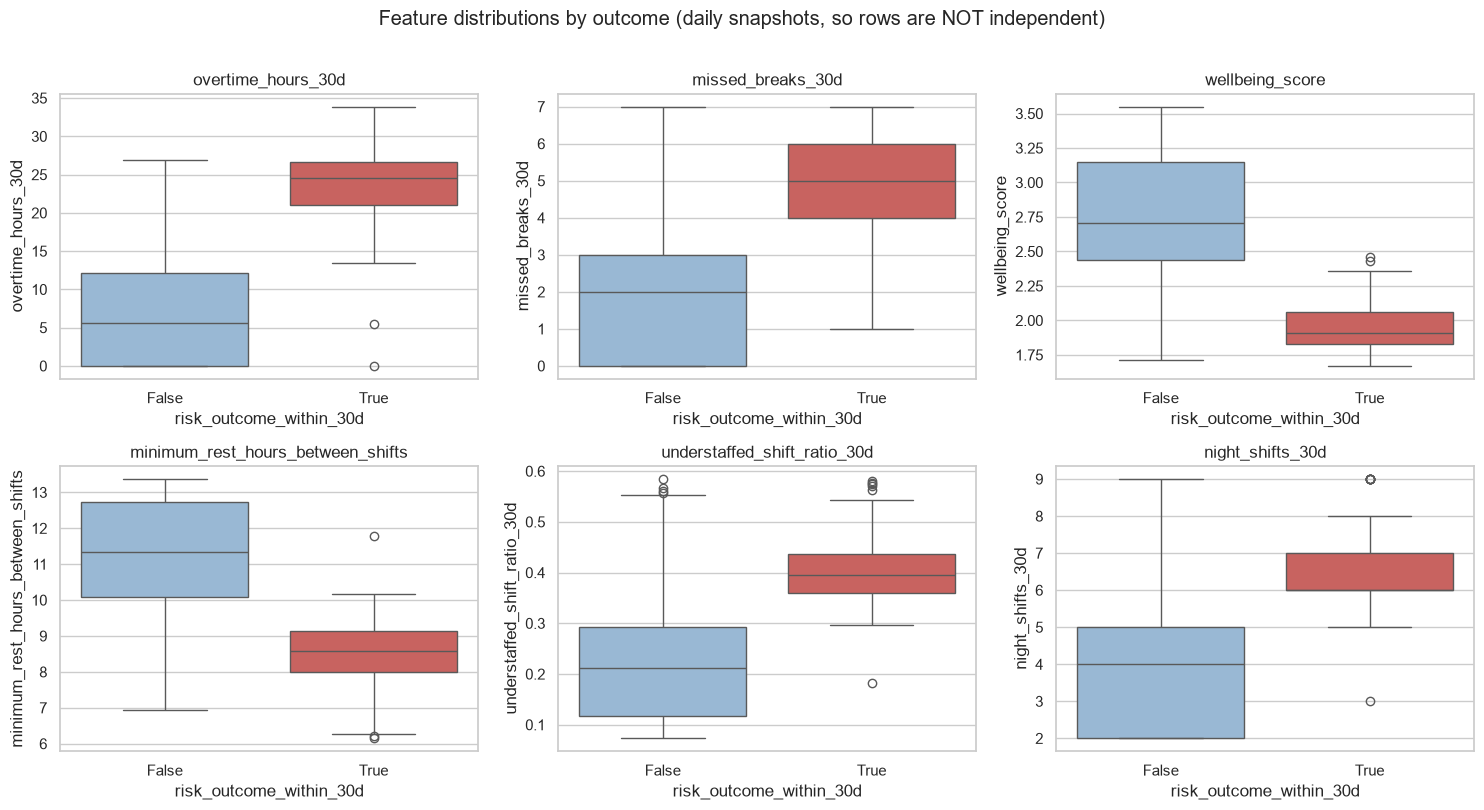

In [14]:
eda_features = ["overtime_hours_30d", "missed_breaks_30d", "wellbeing_score",
                "minimum_rest_hours_between_shifts", "understaffed_shift_ratio_30d", "night_shifts_30d"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), eda_features):
    sns.boxplot(data=df, x=TARGET, y=feat, ax=ax, hue=TARGET, palette={False: "#8fb8de", True: "#d9534f"}, legend=False)
    ax.set_title(feat)
fig.suptitle("Feature distributions by outcome (daily snapshots, so rows are NOT independent)", y=1.01)
plt.tight_layout(); plt.show()

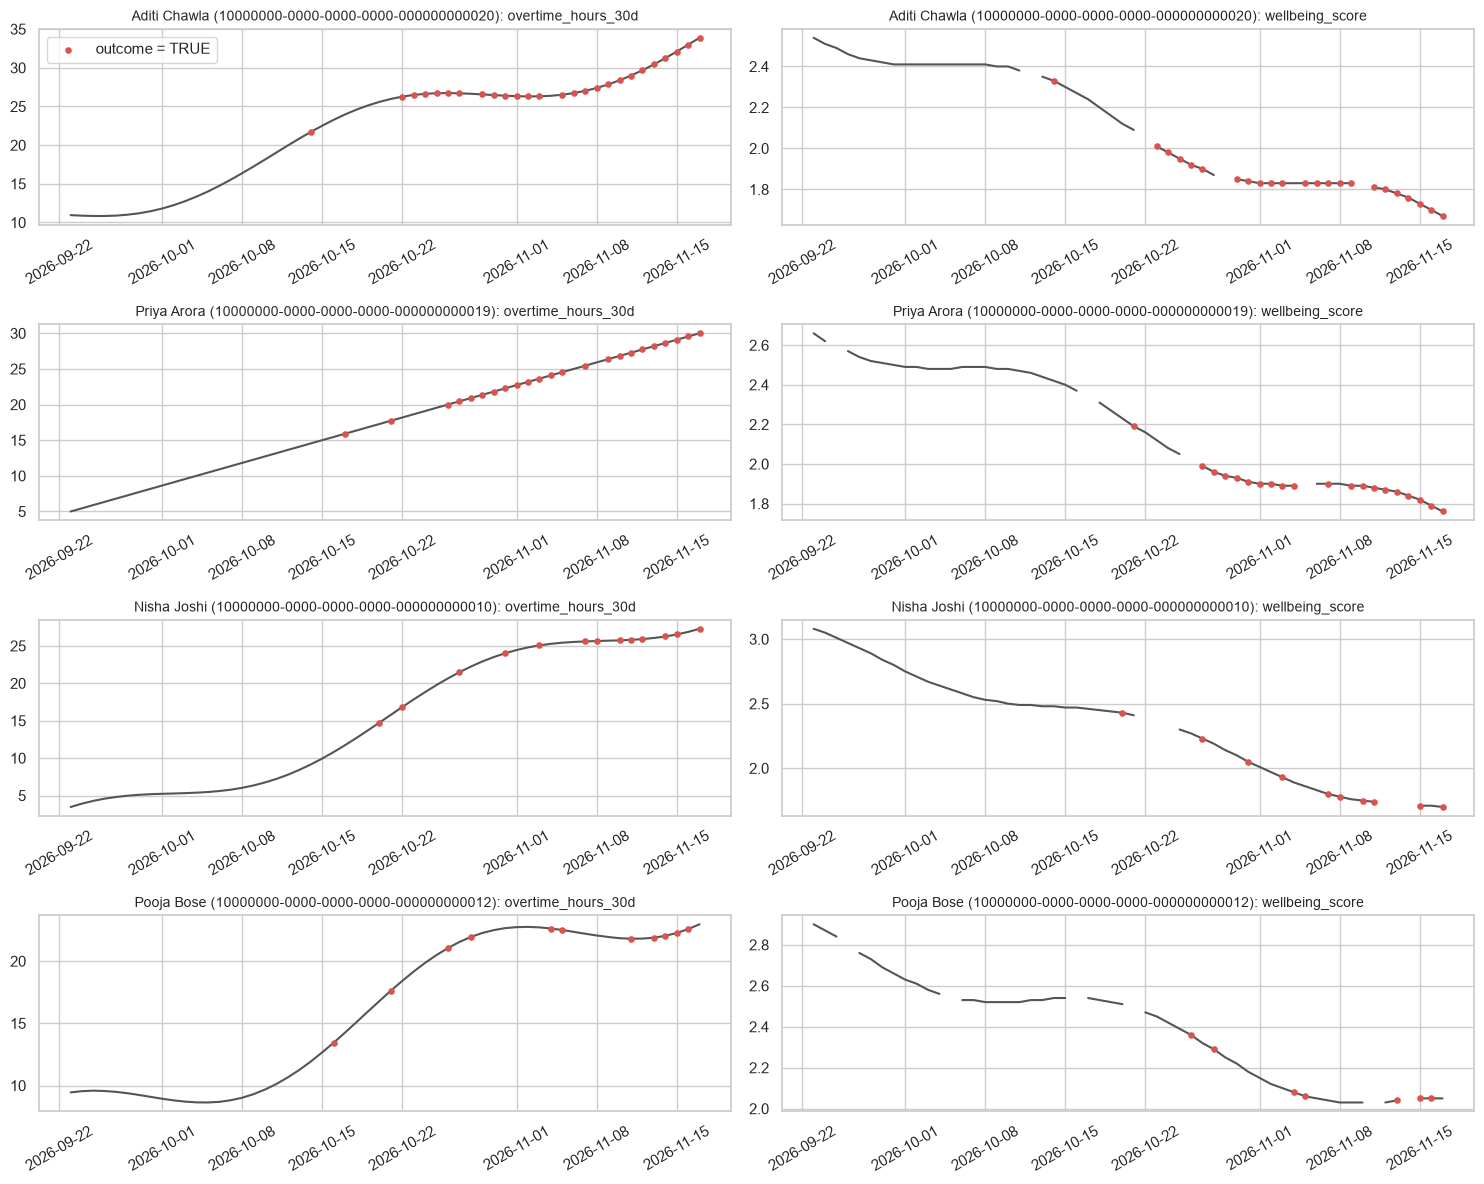

In [15]:
# Trends for the employees with the most positive days. snapshot_date is used for charts only.
trend_emps = positives_per_employee.index[:4]
fig, axes = plt.subplots(len(trend_emps), 2, figsize=(15, 3 * len(trend_emps)), squeeze=False)
for i, emp in enumerate(trend_emps):
    d = df[df["employee_id"] == emp]
    for j, feat in enumerate(["overtime_hours_30d", "wellbeing_score"]):
        ax = axes[i, j]
        ax.plot(d["snapshot_date"], d[feat], color="#555")
        pos = d[d[TARGET]]
        ax.scatter(pos["snapshot_date"], pos[feat], color="#d9534f", s=14, label="outcome = TRUE", zorder=3)
        ax.set_title(f"{employee_label(emp)}: {feat}", fontsize=10)
        ax.tick_params(axis="x", labelrotation=30)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

## 11. Correlation analysis

Spearman (rank) correlation is used because most features are skewed counts. Correlated features are **not** dropped automatically, since XGBoost copes with them well. Two things to keep in mind, though:

- **SHAP credit is shared between correlated features.** If `overtime_hours_30d` and `overtime_ratio_30d` carry the same information, the model may split on either one. Their SHAP values then divide the "overtime effect" between them, so each looks less important than overtime really is. For the manager's "why", consider grouping these features (for example "overtime") when presenting factors.
- Truly redundant pairs (|rho| ≥ 0.9) are flagged below as candidates to drop *later*, if the explanations become confusing.

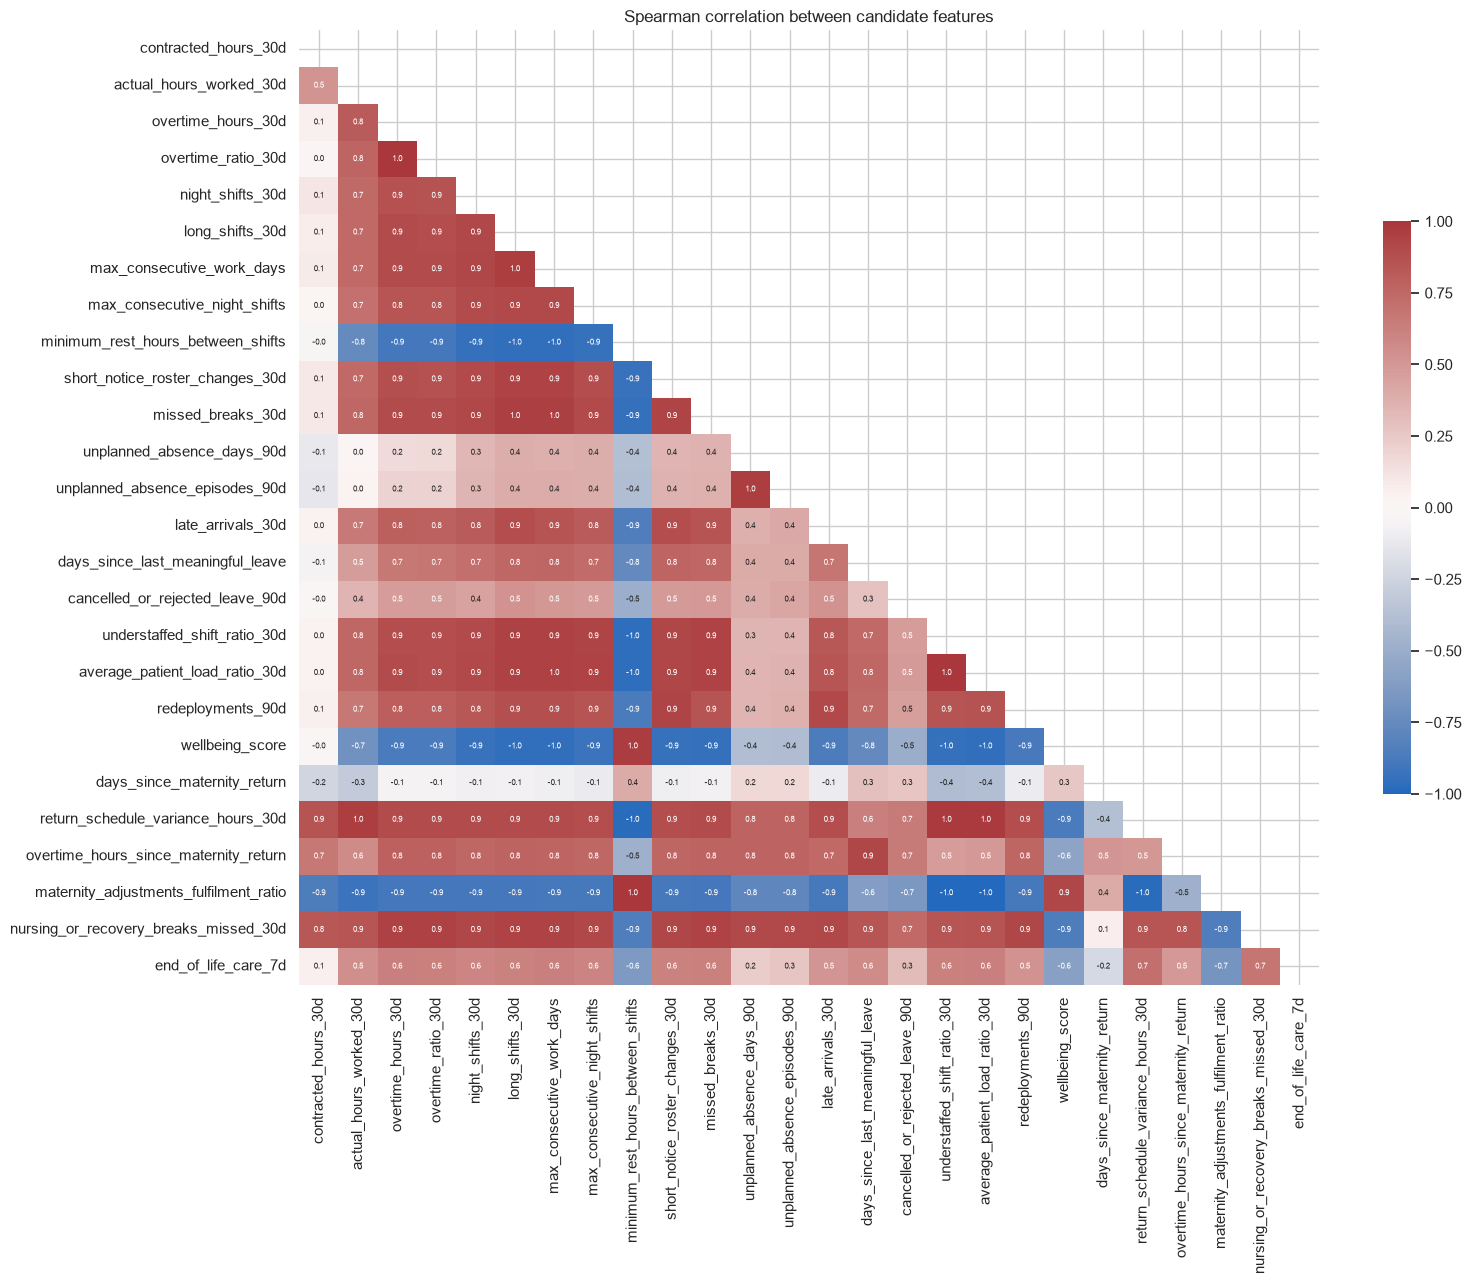

,feature_a,feature_b,spearman_rho,flag
93,minimum_rest_hours_between_shifts,maternity_adjustments_fulfilment_ratio,1.000,likely redundant
128,understaffed_shift_ratio_30d,maternity_adjustments_fulfilment_ratio,-1.000,likely redundant
124,understaffed_shift_ratio_30d,average_patient_load_ratio_30d,0.999,likely redundant
7,overtime_hours_30d,overtime_ratio_30d,0.997,likely redundant
133,average_patient_load_ratio_30d,maternity_adjustments_fulfilment_ratio,-0.994,likely redundant
...,...,...,...,...
115,late_arrivals_30d,understaffed_shift_ratio_30d,0.841,strongly related
77,max_consecutive_night_shifts,late_arrivals_30d,0.819,strongly related
41,night_shifts_30d,late_arrivals_30d,0.816,strongly related
3,actual_hours_worked_30d,overtime_hours_30d,0.814,strongly related


Max |overtime_ratio_30d - overtime/contracted| = 0.0001 (close to 0 means overtime_ratio_30d is a deterministic function of two other features)


In [16]:
corr = df[FEATURES].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(16, 13))
sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 6}, cbar_kws={"shrink": 0.6})
plt.title("Spearman correlation between candidate features")
plt.tight_layout(); plt.show()

pairs = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        rho = corr.loc[a, b]
        if pd.notna(rho) and abs(rho) >= 0.8:
            pairs.append({"feature_a": a, "feature_b": b, "spearman_rho": round(rho, 3),
                          "flag": "likely redundant" if abs(rho) >= 0.9 else "strongly related"})
display(pd.DataFrame(pairs).sort_values("spearman_rho", key=abs, ascending=False) if pairs
        else "No feature pairs with |rho| >= 0.8")

# Mathematical relationship check: overtime_ratio_30d should equal overtime_hours_30d / contracted_hours_30d
implied_ratio = df["overtime_hours_30d"] / df["contracted_hours_30d"].replace(0, np.nan)
print(f"Max |overtime_ratio_30d - overtime/contracted| = {(df['overtime_ratio_30d'] - implied_ratio).abs().max():.4f} "
      "(close to 0 means overtime_ratio_30d is a deterministic function of two other features)")

## 12. Define the feature list

**Leakage prevention:** the feature matrix is built *only* from the explicit `FEATURES` list. The ID/metadata columns, `snapshot_date`, `employee_id`, `risk_label`, the target, and all `employee` master-data fields are excluded by construction. The assertions below make that explicit.

In [17]:
forbidden = set(ID_METADATA_COLUMNS) | set(LEAKAGE_COLUMNS) | {
    "first_name", "last_name", "email", "manager_employee_id", "buddy_employee_id", "job_role"}
assert not forbidden & set(FEATURES), f"Forbidden columns in FEATURES: {forbidden & set(FEATURES)}"

X = df[FEATURES].astype(float)                 # NaNs preserved, NOT imputed
meta = df[["employee_id", "snapshot_date"]].copy()   # kept alongside for grouping and charts only
assert list(X.columns) == FEATURES
print(f"X shape: {X.shape}")

X shape: (1120, 26)


## 13. Define the target

In [18]:
y = df[TARGET].astype(int)
groups = df["employee_id"]
print(f"Target: {TARGET} | positives: {y.sum()} / {len(y)} ({y.mean():.1%})")

Target: risk_outcome_within_30d | positives: 109 / 1120 (9.7%)


## 14. Group-aware train/test split by `employee_id`

**Why not a random row split?** Each employee contributes 56 *consecutive* daily rows built from rolling 7/30/90-day windows. Neighbouring days are almost identical. A random split would put an employee's Tuesday in training and Wednesday in testing, and the model would look excellent just by recognising the employee. All 56 rows of a test employee are therefore kept together in the test set, so the test asks **"how well do we score someone we have never seen?"**

**Split choice:** `GroupShuffleSplit` selects 4 test employees. Because positives are concentrated in a few employees, a random choice of 4 can contain almost no positives. An earlier run drew a test set with only 3 positive rows, which made every metric meaningless. The notebook therefore takes the **first** seeded split whose test positive rate is at least `MIN_TEST_POSITIVE_SHARE` (50%) of the overall rate. This rule is about representativeness and is applied before any metric is computed, so it is not cherry-picking.

**Limitations to state honestly:**
- The test set is only **4 employees**. Metrics depend heavily on *which* 4 they are, and a single person can swing recall by tens of points.
- Section 17b therefore adds **5-fold grouped cross-validation**, where every employee is held out exactly once. That gives a more stable estimate and a spread across folds.
- Even so, 20 employees is a tiny population, and the data is synthetic with cleaner correlations than real life. Treat all metrics as a pipeline sanity check, **not** as evidence of predictive validity.

In [19]:
def choose_group_split(X, y, groups, n_test_groups, random_state, max_tries=500):
    overall_rate = y.mean()
    gss = GroupShuffleSplit(n_splits=max_tries, test_size=n_test_groups, random_state=random_state)
    for attempt, (tr, te) in enumerate(gss.split(X, y, groups)):
        if (y.iloc[te].nunique() == 2 and y.iloc[tr].nunique() == 2
                and y.iloc[te].mean() >= MIN_TEST_POSITIVE_SHARE * overall_rate):
            return tr, te, attempt
    raise RuntimeError("No grouped split met the representativeness rule; lower MIN_TEST_POSITIVE_SHARE")

train_idx, test_idx, attempt = choose_group_split(X, y, groups, N_TEST_EMPLOYEES, RANDOM_STATE)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
meta_train, meta_test = meta.iloc[train_idx], meta.iloc[test_idx]

train_emps, test_emps = set(meta_train["employee_id"]), set(meta_test["employee_id"])
assert train_emps.isdisjoint(test_emps), "Employee leakage between train and test!"
assert meta_test.groupby("employee_id").size().eq(EXPECTED_SNAPSHOTS_PER_EMPLOYEE).all() or not STRICT_VALIDATION

print(f"Split attempt #{attempt} selected")
print(f"Train: {len(train_emps)} employees, {len(X_train)} rows, {y_train.sum()} positives ({y_train.mean():.1%})")
print(f"Test : {len(test_emps)} employees, {len(X_test)} rows, {y_test.sum()} positives ({y_test.mean():.1%})")
print("Test employees:", [employee_label(e) for e in sorted(test_emps)])

Split attempt #1 selected
Train: 16 employees, 896 rows, 76 positives (8.5%)
Test : 4 employees, 224 rows, 33 positives (14.7%)
Test employees: ['Ananya Iyer (10000000-0000-0000-0000-000000000006)', 'Kavya Saxena (10000000-0000-0000-0000-000000000016)', 'Manav Bhatia (10000000-0000-0000-0000-000000000017)', 'Aditi Chawla (10000000-0000-0000-0000-000000000020)']


## 15. Class imbalance: `scale_pos_weight` and probability recalibration

About 10% of rows are positive. A model that always says "no risk" would be about 90% accurate and completely useless, so **accuracy is not the target metric**.

`scale_pos_weight = negatives / positives` makes each positive row count as much as about 9 negatives in the loss. That improves ranking and recall on the rare class.

**Side effect:** weighting multiplies the model's predicted *odds* by about `w`. The raw `predict_proba` therefore runs high, and fixed bands such as 0.6 = HIGH would flag far too many people. This is corrected with the standard prior correction:

$$p_{\text{calibrated}} = \frac{p_{\text{raw}}}{p_{\text{raw}} + (1 - p_{\text{raw}})\cdot w}$$

(that is, divide the odds by `w`). The ranking of employees does not change, because the correction is monotonic.

This simple correction assumes the model is as confident on new employees as on its training data. In practice it isn't, so the correction tends to **under-predict** for unseen people. Section 17c therefore fits a better calibration (Platt scaling) on grouped out-of-fold predictions. `CALIBRATION_METHOD` chooses which one feeds the risk bands and the API.

In [20]:
def compute_scale_pos_weight(y_):
    n_pos, n_neg = int(y_.sum()), int(len(y_) - y_.sum())
    return n_neg / n_pos

def calibrate_probability(raw_p, w):
    """Undo the odds inflation caused by scale_pos_weight = w (prior correction)."""
    raw_p = np.clip(np.asarray(raw_p, dtype=float), 1e-7, 1 - 1e-7)
    return raw_p / (raw_p + (1 - raw_p) * w)

def assign_band(p, bands=RISK_BANDS):
    band = bands[0]["band"]
    for b in sorted(bands, key=lambda b: b["min_probability"]):
        if p >= b["min_probability"]:
            band = b["band"]
    return band

scale_pos_weight = compute_scale_pos_weight(y_train)
print(f"Train negatives/positives = {len(y_train) - y_train.sum()}/{y_train.sum()} "
      f"-> scale_pos_weight = {scale_pos_weight:.2f}")
print(f"Raw score 0.5 corresponds to calibrated probability {calibrate_probability(0.5, scale_pos_weight):.3f}")

Train negatives/positives = 820/76 -> scale_pos_weight = 10.79
Raw score 0.5 corresponds to calibrated probability 0.085


## 16. Train the baseline `XGBClassifier`

In [21]:
model = xgb.XGBClassifier(**XGB_PARAMS, scale_pos_weight=scale_pos_weight)
model.fit(X_train, y_train)          # NaNs passed through untouched (native missing-value handling)

# Probability prediction: column 1 of predict_proba is P(risk_outcome_within_30d = TRUE).
test_raw = model.predict_proba(X_test)[:, 1]
test_cal = calibrate_probability(test_raw, scale_pos_weight)
print(f"Trained {model.n_estimators} trees | test raw score range {test_raw.min():.3f}-{test_raw.max():.3f} "
      f"| calibrated range {test_cal.min():.3f}-{test_cal.max():.3f}")

Trained 300 trees | test raw score range 0.001-0.984 | calibrated range 0.000-0.853


## 17. Evaluate the model on the 4 unseen employees

Main metrics: **ROC-AUC** (ranking quality) and **PR-AUC / average precision** (ranking quality focused on the rare positive class). For comparison, the PR-AUC of a random model equals the positive rate. Precision, recall and F1 use `CLASSIFICATION_THRESHOLD` on the raw score. The Brier score compares the raw and calibrated probabilities (lower is better).

In [22]:
def evaluate(y_true, raw, cal, threshold=CLASSIFICATION_THRESHOLD):
    y_true = np.asarray(y_true)
    y_pred = (raw >= threshold).astype(int)
    both = len(np.unique(y_true)) == 2
    return {
        "rows": len(y_true), "positives": int(y_true.sum()), "positive_rate": y_true.mean(),
        "roc_auc": roc_auc_score(y_true, raw) if both else np.nan,
        "pr_auc": average_precision_score(y_true, raw) if y_true.sum() else np.nan,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "accuracy (not primary)": accuracy_score(y_true, y_pred),
        "brier_raw": brier_score_loss(y_true, raw),
        "brier_calibrated": brier_score_loss(y_true, cal),
        "mean_calibrated_prob": float(np.mean(cal)),
    }

test_metrics = evaluate(y_test, test_raw, test_cal)
display(pd.Series(test_metrics, name="held-out test (4 employees)").to_frame().round(3))
print(classification_report(y_test, (test_raw >= CLASSIFICATION_THRESHOLD).astype(int),
                            target_names=["no outcome", "outcome within 30d"], zero_division=0))

,held-out test (4 employees)
rows,224.000
positives,33.000
positive_rate,0.147
roc_auc,0.971
pr_auc,0.886
precision,0.684
recall,0.788
f1,0.732
accuracy (not primary),0.915
brier_raw,0.054


                    precision    recall  f1-score   support

        no outcome       0.96      0.94      0.95       191
outcome within 30d       0.68      0.79      0.73        33

          accuracy                           0.92       224
         macro avg       0.82      0.86      0.84       224
      weighted avg       0.92      0.92      0.92       224



In [23]:
def band_threshold_table(y_true, cal):
    """How the prototype bands would behave if 'band >= X' triggered an alert."""
    rows = []
    for b in sorted(RISK_BANDS, key=lambda b: b["min_probability"])[1:]:
        flagged = (cal >= b["min_probability"]).astype(int)
        rows.append({"alert if band >=": b["band"], "min_probability": b["min_probability"],
                     "rows_flagged": int(flagged.sum()), "flag_rate": flagged.mean(),
                     "precision": precision_score(y_true, flagged, zero_division=0),
                     "recall": recall_score(y_true, flagged, zero_division=0)})
    return pd.DataFrame(rows).round(3)

print("Prototype risk bands on held-out employees (calibrated probability):")
display(band_threshold_table(y_test, test_cal))

Prototype risk bands on held-out employees (calibrated probability):


,alert if band >=,min_probability,rows_flagged,flag_rate,precision,recall
0,MEDIUM,0.3,28,0.125,0.893,0.758
1,HIGH,0.6,12,0.054,1.000,0.364
2,CRITICAL,0.8,1,0.004,1.000,0.030


### 17b. Grouped 5-fold cross-validation (more stable estimate)

`StratifiedGroupKFold` holds out 4 employees per fold and tries to balance positives across folds. Every employee is scored once by a model that never saw them, which gives **out-of-fold (OOF)** predictions for all 20 employees. If a fold has no positives, its ROC-AUC is undefined (NaN) and is left out of the mean.

In [24]:
sgkf = StratifiedGroupKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
oof_raw = np.zeros(len(X)); oof_cal = np.zeros(len(X))
fold_rows = []
for fold, (tr, te) in enumerate(sgkf.split(X, y, groups)):
    w = compute_scale_pos_weight(y.iloc[tr])
    m = xgb.XGBClassifier(**XGB_PARAMS, scale_pos_weight=w).fit(X.iloc[tr], y.iloc[tr])
    oof_raw[te] = m.predict_proba(X.iloc[te])[:, 1]
    oof_cal[te] = calibrate_probability(oof_raw[te], w)
    fold_rows.append({"fold": fold, "test_employees": groups.iloc[te].nunique(),
                      **evaluate(y.iloc[te], oof_raw[te], oof_cal[te])})

cv_df = pd.DataFrame(fold_rows).set_index("fold")
display(cv_df[["test_employees", "positives", "roc_auc", "pr_auc", "precision", "recall", "f1"]].round(3))
cv_summary = cv_df[["roc_auc", "pr_auc", "precision", "recall", "f1"]].agg(["mean", "std"]).round(3)
display(cv_summary)

oof_metrics = evaluate(y, oof_raw, oof_cal)
display(pd.Series(oof_metrics, name="pooled out-of-fold (all 20 employees)").to_frame().round(3))

,test_employees,positives,roc_auc,pr_auc,precision,recall,f1
fold,,,,,,,
0,4,13,0.901,0.436,0.368,0.538,0.438
1,4,14,0.946,0.505,0.421,0.571,0.485
2,4,17,0.950,0.524,0.429,0.529,0.474
3,4,28,0.918,0.563,0.600,0.429,0.500
4,4,37,0.952,0.753,0.530,0.946,0.680


,roc_auc,pr_auc,precision,recall,f1
mean,0.933,0.556,0.470,0.603,0.515
std,0.023,0.119,0.093,0.199,0.095


,pooled out-of-fold (all 20 employees)
rows,1120.000
positives,109.000
positive_rate,0.097
roc_auc,0.933
pr_auc,0.573
precision,0.490
recall,0.651
f1,0.559
accuracy (not primary),0.900
brier_raw,0.069


### 17c. Probability calibration: Platt scaling on out-of-fold predictions

The prior correction from section 15 assumes the model is as confident on new people as on its training data. On unseen employees its probabilities come out too low, so HIGH and CRITICAL would rarely trigger.

**Platt scaling** fits a 2-parameter logistic curve, `p = sigmoid(a * logit(raw) + b)`, that maps the raw score to a probability. It is fitted on the **out-of-fold** predictions from 17b, where every prediction came from a model that never saw that employee. The fit is therefore calibrated for exactly the situation the API faces: scoring someone's latest snapshot.

Notes:
- The mapping is monotonic, so **ranking, ROC-AUC, PR-AUC and SHAP explanations do not change**. Only the probability scale, and so the bands, changes.
- A logistic fit matches the mean of its training data by construction, so "mean predicted ≈ actual rate" for Platt is expected, not proof. The reliability curve below is the more informative check.

Platt parameters: a = 0.6359, b = -0.9179 | CALIBRATION_METHOD = 'platt'


,mean_predicted_prob,actual_rate,brier (lower is better)
prior correction,0.0518,0.0973,0.0634
Platt (out-of-fold),0.0973,0.0973,0.0570


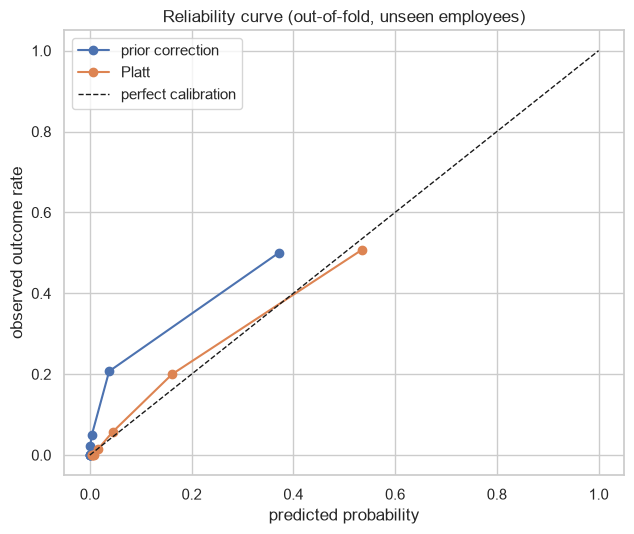

In [25]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))

platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(oof_raw).reshape(-1, 1), y)
PLATT_A, PLATT_B = float(platt.coef_[0, 0]), float(platt.intercept_[0])

def calibrate_platt(raw):
    return 1 / (1 + np.exp(-(PLATT_A * logit(raw) + PLATT_B)))

def calibrate_final(raw, w):
    """The calibration used for risk bands and the API (chosen by CALIBRATION_METHOD)."""
    return calibrate_platt(raw) if CALIBRATION_METHOD == "platt" else calibrate_probability(raw, w)

oof_platt = calibrate_platt(oof_raw)
oof_final = oof_platt if CALIBRATION_METHOD == "platt" else oof_cal
print(f"Platt parameters: a = {PLATT_A:.4f}, b = {PLATT_B:.4f} | CALIBRATION_METHOD = {CALIBRATION_METHOD!r}")

display(pd.DataFrame({
    "mean_predicted_prob": [oof_cal.mean(), oof_platt.mean()],
    "actual_rate": [y.mean(), y.mean()],
    "brier (lower is better)": [brier_score_loss(y, oof_cal), brier_score_loss(y, oof_platt)],
}, index=["prior correction", "Platt (out-of-fold)"]).round(4))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for label, probs in [("prior correction", oof_cal), ("Platt", oof_platt)]:
    frac_pos, mean_pred = calibration_curve(y, probs, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=label)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed outcome rate")
ax.set_title("Reliability curve (out-of-fold, unseen employees)"); ax.legend()
plt.tight_layout(); plt.show()

### 17d. Risk bands and alert threshold on unseen employees

This shows how the configured `RISK_BANDS` behave on out-of-fold probabilities, as if the model were scoring people it has never seen. Suggested agent mapping: **MEDIUM → supportive nudge or buddy**, **HIGH/CRITICAL → manager alert**.

The cell also suggests an alert threshold that catches `TARGET_RECALL_FOR_ALERTS` (80%) of at-risk days, and shows the precision that costs.

In [26]:
print("Configured risk bands on out-of-fold predictions:")
display(band_threshold_table(y, oof_final))

grid = []
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:
    flagged = (oof_final >= t).astype(int)
    grid.append({"threshold": t, "flag_rate": flagged.mean(),
                 "precision": precision_score(y, flagged, zero_division=0),
                 "recall": recall_score(y, flagged, zero_division=0)})
print("Precision / recall trade-off by probability threshold:")
display(pd.DataFrame(grid).round(3))

prec_c, rec_c, thr_c = precision_recall_curve(y, oof_final)
meets = np.where(rec_c[:-1] >= TARGET_RECALL_FOR_ALERTS)[0]
SUGGESTED_ALERT_THRESHOLD = float(thr_c[meets[-1]]) if len(meets) else float(thr_c[0])
_i = meets[-1] if len(meets) else 0
print(f"Suggested alert threshold for >= {TARGET_RECALL_FOR_ALERTS:.0%} recall: {SUGGESTED_ALERT_THRESHOLD:.3f} "
      f"(recall {rec_c[_i]:.2f}, precision {prec_c[_i]:.2f}, flags {np.mean(oof_final >= SUGGESTED_ALERT_THRESHOLD):.1%} of days)")

Configured risk bands on out-of-fold predictions:


,alert if band >=,min_probability,rows_flagged,flag_rate,precision,recall
0,MEDIUM,0.3,143,0.128,0.497,0.651
1,HIGH,0.6,43,0.038,0.767,0.303
2,CRITICAL,0.8,8,0.007,0.625,0.046


Precision / recall trade-off by probability threshold:


,threshold,flag_rate,precision,recall
0,0.05,0.292,0.315,0.945
1,0.10,0.229,0.383,0.899
2,0.15,0.188,0.424,0.817
3,0.20,0.160,0.464,0.761
4,0.30,0.128,0.497,0.651
5,0.40,0.098,0.536,0.541
6,0.50,0.066,0.635,0.431
7,0.60,0.038,0.767,0.303
8,0.70,0.017,0.684,0.119
9,0.80,0.007,0.625,0.046


Suggested alert threshold for >= 80% recall: 0.154 (recall 0.81, precision 0.43, flags 18.5% of days)


### 17e. Early warning by employee (out-of-fold)

Judges care about people, not rows. For each employee who has any at-risk days, this asks: **were they flagged (band ≥ MEDIUM), and how many days before their first at-risk day?** It also counts employees who were never at risk but still got flagged (false-alarm people). All probabilities come from models that never saw the employee.

In [27]:
EARLY_WARNING_THRESHOLD = next(b["min_probability"] for b in RISK_BANDS if b["band"] == "MEDIUM")
ew = meta.assign(prob=oof_final, actual=y.values)
ew_rows, false_alarm_people = [], 0
for emp, d in ew.groupby("employee_id"):
    d = d.sort_values("snapshot_date")
    flagged = d["prob"] >= EARLY_WARNING_THRESHOLD
    if d["actual"].sum() == 0:
        false_alarm_people += int(flagged.any())
        continue
    first_pos = d.loc[d["actual"] == 1, "snapshot_date"].min()
    first_flag = d.loc[flagged, "snapshot_date"].min() if flagged.any() else pd.NaT
    ew_rows.append({
        "employee": employee_label(emp),
        "at_risk_days": int(d["actual"].sum()),
        "at_risk_days_flagged": int((flagged & (d["actual"] == 1)).sum()),
        "first_at_risk_day": first_pos.date(),
        "first_flag_day": first_flag.date() if pd.notna(first_flag) else None,
        "days_early(+)/late(-)": (first_pos - first_flag).days if pd.notna(first_flag) else None,
    })
ew_df = pd.DataFrame(ew_rows)
display(ew_df)
n_at_risk = len(ew_df)
n_caught = int((ew_df["at_risk_days_flagged"] > 0).sum()) if n_at_risk else 0
n_never = ew["employee_id"].nunique() - n_at_risk
print(f"At-risk employees flagged (band >= MEDIUM, p >= {EARLY_WARNING_THRESHOLD}): {n_caught} / {n_at_risk}")
print(f"Never-at-risk employees with at least one flag (false-alarm people): {false_alarm_people} / {n_never}")

,employee,at_risk_days,at_risk_days_flagged,first_at_risk_day,first_flag_day,days_early(+)/late(-)
0,Arjun Mehta (10000000-0000-0000-0000-000000000...,3,2,2026-10-20,2026-10-18,2
1,Ishita Kapoor (10000000-0000-0000-0000-0000000...,2,2,2026-10-21,2026-10-20,1
2,Vikram Rao (10000000-0000-0000-0000-000000000009),9,7,2026-09-29,2026-10-22,-23
3,Nisha Joshi (10000000-0000-0000-0000-000000000...,13,7,2026-10-20,2026-10-30,-10
4,Karan Malhotra (10000000-0000-0000-0000-000000...,10,5,2026-10-26,2026-10-30,-4
5,Pooja Bose (10000000-0000-0000-0000-000000000012),11,6,2026-10-16,2026-09-26,20
6,Rahul Khanna (10000000-0000-0000-0000-00000000...,4,1,2026-10-24,2026-11-07,-14
7,Aditya Menon (10000000-0000-0000-0000-00000000...,1,0,2026-11-10,2026-11-17,-7
8,Kavya Saxena (10000000-0000-0000-0000-00000000...,3,2,2026-11-11,2026-10-21,21
9,Manav Bhatia (10000000-0000-0000-0000-00000000...,4,2,2026-11-07,2026-11-08,-1


At-risk employees flagged (band >= MEDIUM, p >= 0.3): 11 / 12
Never-at-risk employees with at least one flag (false-alarm people): 1 / 8


## 18. Confusion matrix

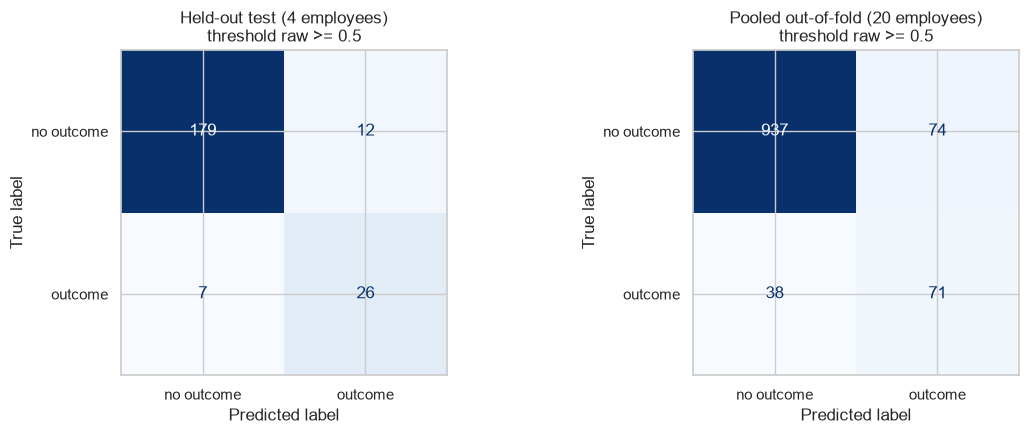

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, yt, raw) in zip(axes, [("Held-out test (4 employees)", y_test, test_raw),
                                       ("Pooled out-of-fold (20 employees)", y, oof_raw)]):
    cm = confusion_matrix(yt, (raw >= CLASSIFICATION_THRESHOLD).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["no outcome", "outcome"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title}\nthreshold raw >= {CLASSIFICATION_THRESHOLD}")
plt.tight_layout(); plt.show()

## 19. ROC curve

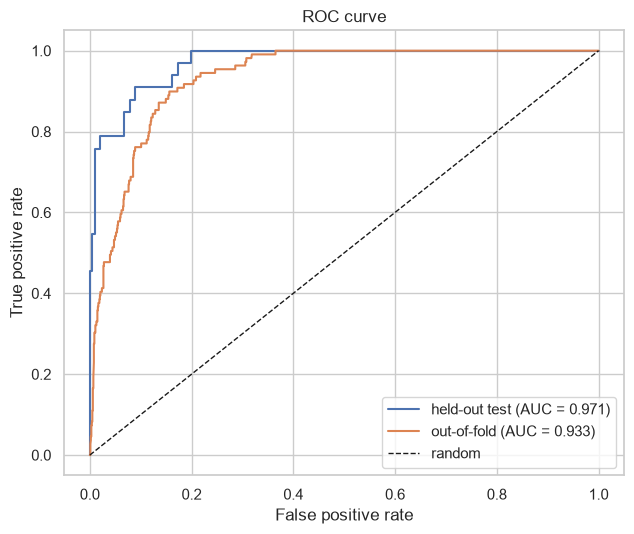

In [29]:
plt.figure(figsize=(6.5, 5.5))
for label, yt, raw in [("held-out test", y_test, test_raw), ("out-of-fold", y, oof_raw)]:
    if len(np.unique(yt)) == 2:
        fpr, tpr, _ = roc_curve(yt, raw)
        plt.plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(yt, raw):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curve")
plt.legend(); plt.tight_layout(); plt.show()

## 20. Precision-recall curve

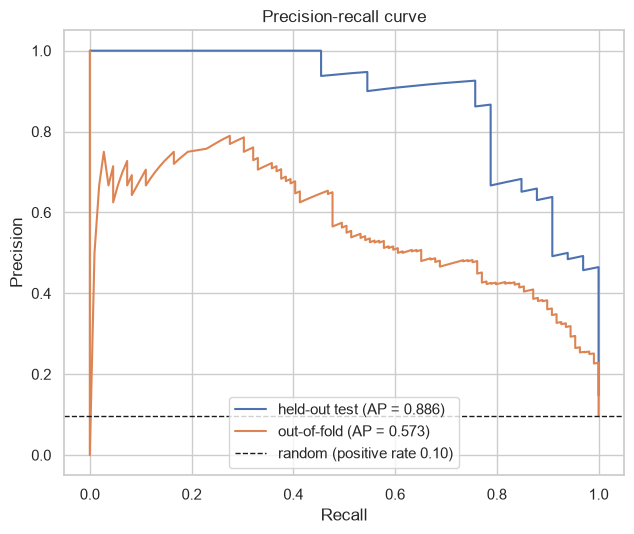

In [30]:
plt.figure(figsize=(6.5, 5.5))
for label, yt, raw in [("held-out test", y_test, test_raw), ("out-of-fold", y, oof_raw)]:
    prec, rec, _ = precision_recall_curve(yt, raw)
    plt.plot(rec, prec, label=f"{label} (AP = {average_precision_score(yt, raw):.3f})")
plt.axhline(y.mean(), color="k", ls="--", lw=1, label=f"random (positive rate {y.mean():.2f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-recall curve")
plt.legend(); plt.tight_layout(); plt.show()

## 21. Feature importance (XGBoost gain)

Gain is the average improvement in the loss when a feature is used in a split. It is **global** and has **no direction**, and correlated features split it between them. Use SHAP (next section) for direction and for explaining individual predictions.

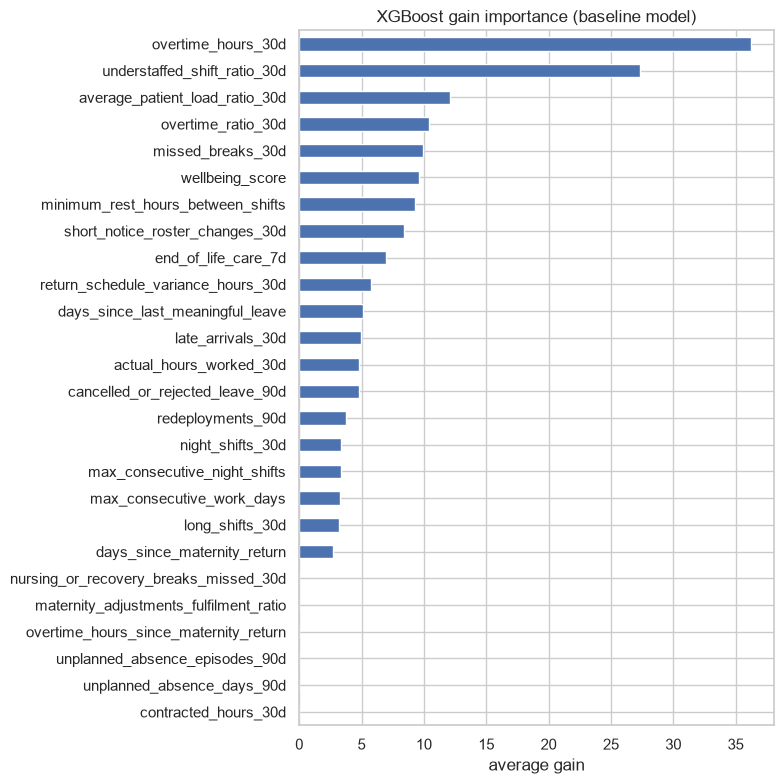

Features never used in a split: ['contracted_hours_30d', 'unplanned_absence_days_90d', 'unplanned_absence_episodes_90d', 'overtime_hours_since_maternity_return', 'maternity_adjustments_fulfilment_ratio', 'nursing_or_recovery_breaks_missed_30d']


In [31]:
gain = model.get_booster().get_score(importance_type="gain")
importance = pd.Series({f: gain.get(f, 0.0) for f in FEATURES}).sort_values()
plt.figure(figsize=(8, 8))
importance.plot.barh(color="#4c72b0")
plt.title("XGBoost gain importance (baseline model)"); plt.xlabel("average gain")
plt.tight_layout(); plt.show()
print("Features never used in a split:", [f for f in FEATURES if gain.get(f, 0) == 0] or "none")

## 22. SHAP explainability

**TreeSHAP** splits each prediction exactly into one contribution per feature plus a base value:

`base_value + sum(shap_values) = raw model log-odds`

- SHAP values are in **log-odds units**. A positive value means the feature **increased** risk for this person, and a negative value means it **decreased** risk.
- The class-weight recalibration subtracts the constant `log(w)` from the log-odds. That shifts only the base value, so **per-feature SHAP values are unaffected**.
- XGBoost can compute the same TreeSHAP values natively (`pred_contribs=True`). The FastAPI inference module uses that native route so the server needs only `xgboost`, not `shap`. The check below confirms the two routes agree.
- **Correlated features share SHAP credit** (see section 11), and a NULL maternity feature can still have a non-zero SHAP value. That reflects the "not applicable" branch the trees learned.

In [32]:
native = model.get_booster().predict(xgb.DMatrix(X_test, missing=np.nan), pred_contribs=True)
native_values, native_base = native[:, :-1], native[:, -1]

try:
    explainer = shap.TreeExplainer(model)
    shap_exp = explainer(X_test)
    diff = np.abs(shap_exp.values - native_values).max()
    print(f"shap.TreeExplainer vs XGBoost native pred_contribs: max abs difference = {diff:.2e}")
except Exception as exc:     # some shap/xgboost version combinations disagree on model parsing
    print(f"shap.TreeExplainer failed ({type(exc).__name__}: {exc}); using XGBoost native TreeSHAP values")
    shap_exp = shap.Explanation(values=native_values, base_values=native_base,
                                data=X_test.values, feature_names=FEATURES)

recon = shap_exp.base_values + shap_exp.values.sum(axis=1)
raw_logodds = np.log(test_raw / (1 - test_raw))
print(f"Additivity check (base + sum(SHAP) == log-odds): max error = {np.abs(recon - raw_logodds).max():.2e}")

shap.TreeExplainer vs XGBoost native pred_contribs: max abs difference = 0.00e+00
Additivity check (base + sum(SHAP) == log-odds): max error = 5.25e-06


C:\Users\garobe\Desktop\shiftguard-model\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


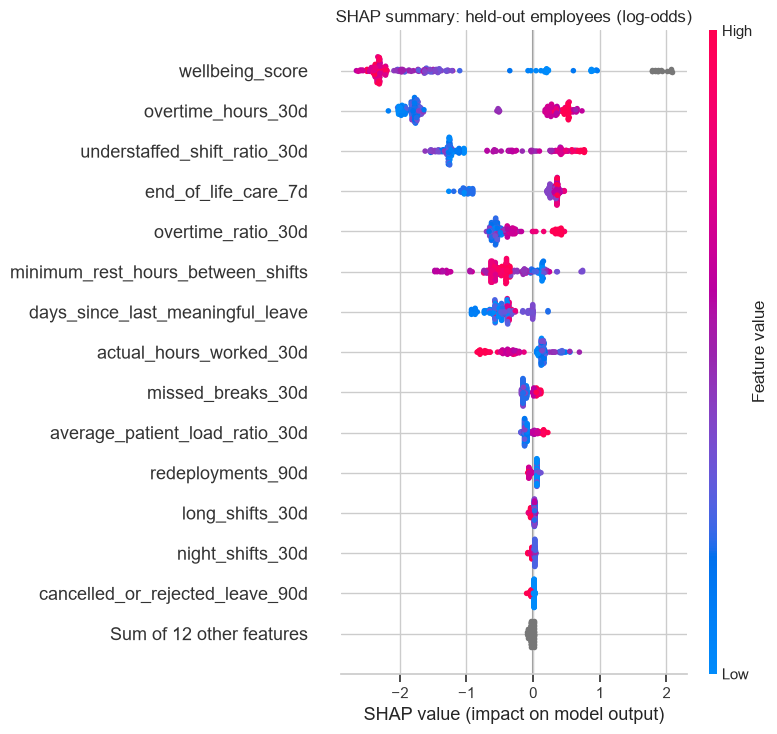

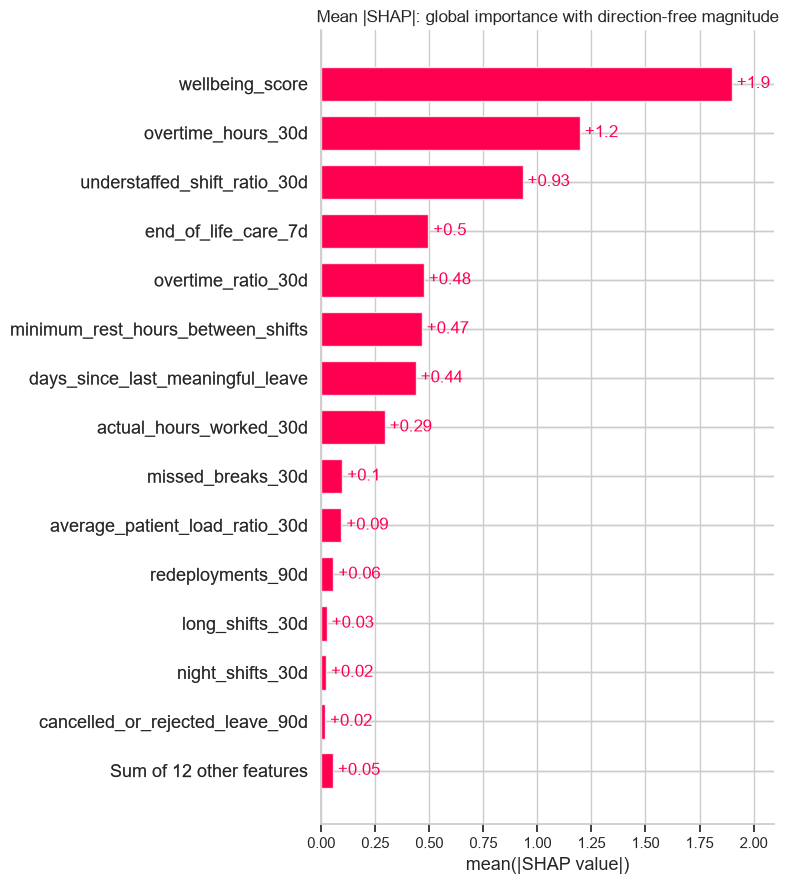

In [33]:
shap.plots.beeswarm(shap_exp, max_display=15, show=False)
plt.title("SHAP summary: held-out employees (log-odds)"); plt.tight_layout(); plt.show()

shap.plots.bar(shap_exp, max_display=15, show=False)
plt.title("Mean |SHAP|: global importance with direction-free magnitude"); plt.tight_layout(); plt.show()

## 23. Example: an individual prediction for an unseen employee

The example uses the held-out employee with the highest average predicted risk and takes their **latest** snapshot. That is what the manager dashboard would show "today". The trend chart shows how the calibrated probability changes over the 8 weeks for each test employee.

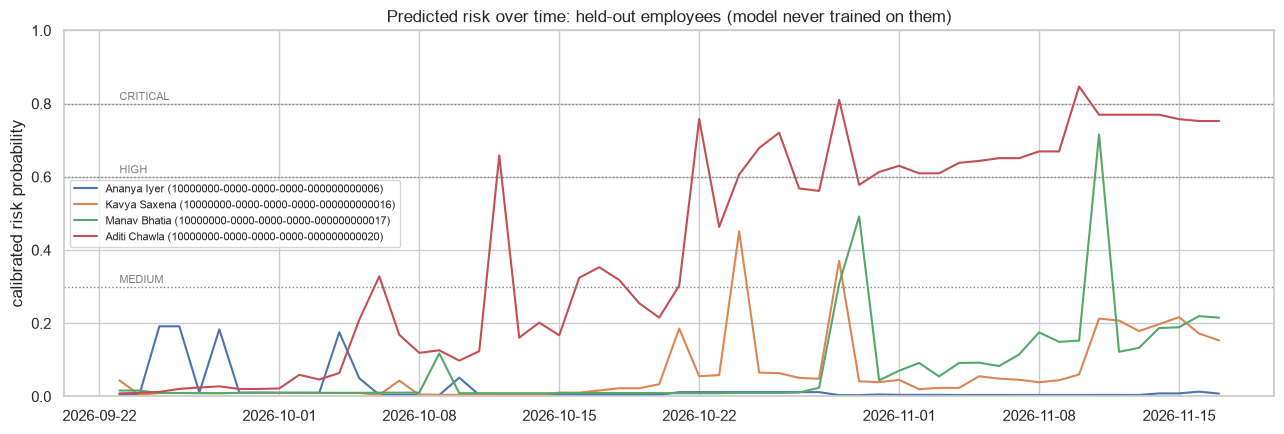

Employee:          Aditi Chawla (10000000-0000-0000-0000-000000000020)
Snapshot date:     2026-11-17
Raw model score:   0.961  (class-weighted, not a probability)
Risk probability:  0.753  -> band HIGH
Actual outcome:    True


In [34]:
test_prob = calibrate_final(test_raw, scale_pos_weight)      # same calibration the API uses
test_view = meta_test.assign(raw_score=test_raw, risk_probability=test_prob, actual=y_test.values,
                             risk_band=[assign_band(p) for p in test_prob]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 4.5))
for emp, d in test_view.groupby("employee_id"):
    ax.plot(d["snapshot_date"], d["risk_probability"], label=employee_label(emp))
for b in RISK_BANDS[1:]:
    ax.axhline(b["min_probability"], ls=":", color="grey", lw=1)
    ax.text(test_view["snapshot_date"].min(), b["min_probability"] + 0.01, b["band"], fontsize=8, color="grey")
ax.set_ylim(0, 1); ax.set_ylabel("calibrated risk probability")
ax.set_title("Predicted risk over time: held-out employees (model never trained on them)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

example_emp = test_view.groupby("employee_id")["risk_probability"].mean().idxmax()
example_pos = int(test_view[test_view["employee_id"] == example_emp]["snapshot_date"].idxmax())
ex = test_view.iloc[example_pos]
print(f"Employee:          {employee_label(example_emp)}")
print(f"Snapshot date:     {ex['snapshot_date'].date()}")
print(f"Raw model score:   {ex['raw_score']:.3f}  (class-weighted, not a probability)")
print(f"Risk probability:  {ex['risk_probability']:.3f}  -> band {ex['risk_band']}")
print(f"Actual outcome:    {bool(ex['actual'])}")

## 24. Top SHAP risk contributors for that prediction

This is the structure that will be stored in `risk_explanation`. It shows the feature, its actual value, the SHAP value and the direction. Gemini can then turn the top factors into the plain-language "why" for the manager. The manager never sees raw check-in text, only these factors.

,feature,value,shap_value,direction
0,wellbeing_score,1.6700,0.8762,INCREASES_RISK
1,understaffed_shift_ratio_30d,0.4860,0.7308,INCREASES_RISK
2,actual_hours_worked_30d,193.8800,-0.7237,DECREASES_RISK
3,overtime_hours_30d,33.8800,0.5292,INCREASES_RISK
4,overtime_ratio_30d,0.2118,0.4239,INCREASES_RISK
5,end_of_life_care_7d,5.0000,0.3546,INCREASES_RISK
6,minimum_rest_hours_between_shifts,6.1500,0.1383,INCREASES_RISK
7,missed_breaks_30d,7.0000,0.1138,INCREASES_RISK
8,average_patient_load_ratio_30d,1.3700,0.1067,INCREASES_RISK
9,night_shifts_30d,8.0000,-0.0782,DECREASES_RISK


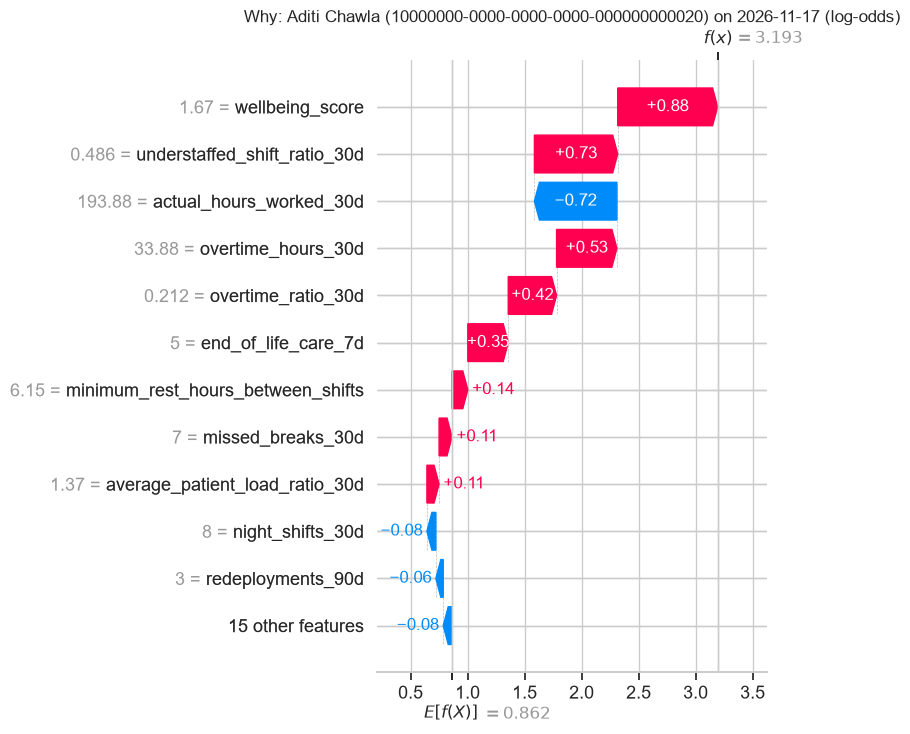

In [35]:
row_values = X_test.iloc[example_pos]
row_shap = shap_exp.values[example_pos]
contrib = (pd.DataFrame({"feature": FEATURES, "value": row_values.values, "shap_value": row_shap})
             .assign(direction=lambda t: np.where(t["shap_value"] > 0, "INCREASES_RISK", "DECREASES_RISK"),
                     abs_shap=lambda t: t["shap_value"].abs())
             .query("abs_shap > 0").sort_values("abs_shap", ascending=False).drop(columns="abs_shap"))
display(contrib.head(10).round(4).reset_index(drop=True))

shap.plots.waterfall(shap_exp[example_pos], max_display=12, show=False)
plt.title(f"Why: {employee_label(example_emp)} on {ex['snapshot_date'].date()} (log-odds)")
plt.tight_layout(); plt.show()

## 25. Refit on all 20 employees and save the trained model

The evaluation model above saw only 16 employees. For the deployed artifact, the **same configuration** is refit on all 20 employees with `scale_pos_weight` recomputed on the full data. The reported metrics (held-out test and grouped CV) are estimates for this procedure. The final model has no held-out test of its own, because there are no employees left to hold out.

`model.json` is XGBoost's portable JSON format. It stores the feature names, so an input in the wrong order is caught when the model loads.

In [36]:
final_scale_pos_weight = compute_scale_pos_weight(y)
final_model = xgb.XGBClassifier(**XGB_PARAMS, scale_pos_weight=final_scale_pos_weight)
final_model.fit(X, y)

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
final_model.save_model(MODEL_PATH)

trained_at = datetime.now(timezone.utc)
model_config = {
    "model_version": f"shiftguard-xgb-{trained_at:%Y%m%d-%H%M%S}",
    "trained_at_utc": trained_at.isoformat(),
    "target": TARGET,
    "feature_names": FEATURES,
    "maternity_features_null_means_not_applicable": MATERNITY_FEATURES,
    "training_rows": int(len(X)), "training_employees": int(groups.nunique()),
    "training_positive_rate": float(y.mean()),
    "scale_pos_weight": float(final_scale_pos_weight),
    "calibration": (
        {"method": "platt", "a": PLATT_A, "b": PLATT_B,
         "fitted_on": "grouped out-of-fold predictions (unseen employees)",
         "formula": "p = 1 / (1 + exp(-(a * ln(raw / (1 - raw)) + b)))"}
        if CALIBRATION_METHOD == "platt" else
        {"method": "prior_correction_for_scale_pos_weight",
         "formula": "p = raw / (raw + (1 - raw) * scale_pos_weight)"}),
    "suggested_alert_threshold": {"probability": SUGGESTED_ALERT_THRESHOLD,
                                  "target_recall": TARGET_RECALL_FOR_ALERTS},
    "classification_threshold_raw": CLASSIFICATION_THRESHOLD,
    "risk_bands": RISK_BANDS,
    "risk_bands_note": "Prototype application thresholds on calibrated probability; NOT clinically validated.",
    "top_k_factors": TOP_K_FACTORS,
    "shap_units": "log_odds",
    "xgb_params": XGB_PARAMS,
    "library_versions": {"xgboost": xgb.__version__, "scikit-learn": sklearn.__version__, "pandas": pd.__version__},
    "evaluation": {
        "heldout_test_4_employees": {k: float(v) for k, v in test_metrics.items()},
        "grouped_cv_mean": {k: float(v) for k, v in cv_summary.loc["mean"].items()},
        "grouped_cv_std": {k: float(v) for k, v in cv_summary.loc["std"].items()},
        "pooled_out_of_fold": {k: float(v) for k, v in oof_metrics.items()},
        "pooled_out_of_fold_brier_final_calibration": float(brier_score_loss(y, oof_final)),
        "early_warning_employees_caught": f"{n_caught}/{n_at_risk}",
    },
    "disclaimer": "Trained on synthetic data for a hackathon prototype. Not clinically validated.",
}
MODEL_CONFIG_PATH.write_text(json.dumps(model_config, indent=2, default=str))
print(f"Saved {MODEL_PATH} and {MODEL_CONFIG_PATH} | scale_pos_weight = {final_scale_pos_weight:.2f}")

Saved model_artifacts\model.json and model_artifacts\model_config.json | scale_pos_weight = 9.28


## 26. Save the exact feature order expected by FastAPI

At inference time FastAPI **must** build its input in this exact order. The inference module enforces this: it reorders incoming dicts by `feature_names.json`, and it refuses to start if the saved booster's feature names disagree with that file.

In [37]:
FEATURE_NAMES_PATH.write_text(json.dumps(FEATURES, indent=2))
booster_names = final_model.get_booster().feature_names
assert list(booster_names) == FEATURES, "Booster feature order differs from FEATURES!"
print(f"Saved {FEATURE_NAMES_PATH} ({len(FEATURES)} features, order matches booster)")
for i, f in enumerate(FEATURES):
    print(f"{i:>2}  {f}")

Saved model_artifacts\feature_names.json (26 features, order matches booster)
 0  contracted_hours_30d
 1  actual_hours_worked_30d
 2  overtime_hours_30d
 3  overtime_ratio_30d
 4  night_shifts_30d
 5  long_shifts_30d
 6  max_consecutive_work_days
 7  max_consecutive_night_shifts
 8  minimum_rest_hours_between_shifts
 9  short_notice_roster_changes_30d
10  missed_breaks_30d
11  unplanned_absence_days_90d
12  unplanned_absence_episodes_90d
13  late_arrivals_30d
14  days_since_last_meaningful_leave
15  cancelled_or_rejected_leave_90d
16  understaffed_shift_ratio_30d
17  average_patient_load_ratio_30d
18  redeployments_90d
19  wellbeing_score
20  days_since_maternity_return
21  return_schedule_variance_hours_30d
22  overtime_hours_since_maternity_return
23  maternity_adjustments_fulfilment_ratio
24  nursing_or_recovery_breaks_missed_30d
25  end_of_life_care_7d


## 27. Reusable prediction function (FastAPI-ready)

The next cell writes `model_artifacts/risk_inference.py`. It is a small, dependency-light module (numpy, pandas, xgboost; no shap or sklearn) that FastAPI can import. The notebook then imports it and tests it against the saved artifacts, so the notebook and the API share **one** implementation.

In [38]:
%%writefile model_artifacts/risk_inference.py
"""ShiftGuard risk-model inference (FastAPI-ready).

Loads the artifacts produced by the training notebook:
    model.json          XGBoost model (portable JSON)
    feature_names.json  exact training feature order
    model_config.json   calibration constant, risk bands, metadata

Usage (FastAPI):
    from risk_inference import predict_employee_risk
    result = predict_employee_risk(snapshot_feature_dict)

Prototype on synthetic data. Risk bands are NOT clinically validated.
"""
from __future__ import annotations

import json
import math
from pathlib import Path
from typing import Any, Mapping, Optional

import numpy as np
import pandas as pd
import xgboost as xgb

DEFAULT_ARTIFACT_DIR = Path(__file__).resolve().parent


class RiskModel:
    def __init__(self, artifact_dir: Path | str = DEFAULT_ARTIFACT_DIR):
        artifact_dir = Path(artifact_dir)
        self.feature_names: list[str] = json.loads((artifact_dir / "feature_names.json").read_text())
        self.config: dict = json.loads((artifact_dir / "model_config.json").read_text())
        self.model = xgb.XGBClassifier()
        self.model.load_model(str(artifact_dir / "model.json"))

        booster_names = self.model.get_booster().feature_names
        if booster_names is not None and list(booster_names) != self.feature_names:
            raise ValueError("model.json feature names do not match feature_names.json order")

        self.scale_pos_weight = float(self.config["scale_pos_weight"])
        self.risk_bands = sorted(self.config["risk_bands"], key=lambda b: b["min_probability"])
        self.top_k = int(self.config.get("top_k_factors", 5))

    # -- 1-4: validate names, enforce training order, preserve NULLs, build a DataFrame
    def _to_frame(self, feature_dict: Mapping[str, Any]) -> pd.DataFrame:
        missing = [f for f in self.feature_names if f not in feature_dict]
        if missing:
            # A key must be present even when not applicable. Send None/null explicitly, so a
            # "forgot to send it" bug is never confused with "not applicable".
            raise ValueError(f"Missing required features (send null if not applicable): {missing}")
        row = {}
        for f in self.feature_names:                       # exact training order
            v = feature_dict[f]
            if v is None or (isinstance(v, float) and math.isnan(v)):
                row[f] = np.nan                            # NULL stays missing; never coerced to 0
                continue
            if isinstance(v, bool):
                raise ValueError(f"Feature {f!r} must be numeric, got bool")
            try:
                fv = float(v)
            except (TypeError, ValueError):
                raise ValueError(f"Feature {f!r} must be numeric or null, got {v!r}") from None
            if math.isinf(fv):
                raise ValueError(f"Feature {f!r} is infinite")
            row[f] = fv
        return pd.DataFrame([row], columns=self.feature_names, dtype=float)

    def calibrate(self, raw: float) -> float:
        """Map the raw class-weighted score to a calibrated probability (method from model_config.json)."""
        raw = min(max(raw, 1e-7), 1 - 1e-7)
        cal = self.config.get("calibration", {})
        if cal.get("method") == "platt":
            z = float(cal["a"]) * math.log(raw / (1 - raw)) + float(cal["b"])
            z = max(min(z, 700.0), -700.0)
            return 1.0 / (1.0 + math.exp(-z))
        return raw / (raw + (1 - raw) * self.scale_pos_weight)   # prior correction

    def band_for(self, probability: float) -> str:
        band = self.risk_bands[0]["band"]
        for b in self.risk_bands:
            if probability >= b["min_probability"]:
                band = b["band"]
        return band

    def predict(self, feature_dict: Mapping[str, Any], top_k: Optional[int] = None) -> dict:
        X = self._to_frame(feature_dict)
        # 5-7: probability (raw class-weighted score -> calibrated probability) and band
        raw = float(self.model.predict_proba(X)[:, 1][0])
        probability = self.calibrate(raw)
        # 8: TreeSHAP contributions natively from XGBoost (log-odds; last column = base value)
        contribs = self.model.get_booster().predict(xgb.DMatrix(X, missing=np.nan), pred_contribs=True)[0]
        shap_values, base_value = contribs[:-1], float(contribs[-1])
        # 9: top contributing features by |SHAP|
        k = self.top_k if top_k is None else top_k
        order = [i for i in np.argsort(-np.abs(shap_values)) if shap_values[i] != 0][:k]
        top_factors = []
        for i in order:
            value = X.iat[0, i]
            top_factors.append({
                "feature": self.feature_names[i],
                "value": None if np.isnan(value) else round(float(value), 4),
                "shap_value": round(float(shap_values[i]), 4),
                "direction": "INCREASES_RISK" if shap_values[i] > 0 else "DECREASES_RISK",
            })
        return {
            "risk_probability": round(probability, 4),
            "risk_band": self.band_for(probability),
            "raw_model_score": round(raw, 4),
            "top_factors": top_factors,
            "shap_base_value": round(base_value, 4),
            "shap_units": "log_odds",
            "model_version": self.config.get("model_version"),
        }


_default_model: Optional[RiskModel] = None


def get_model(artifact_dir: Path | str | None = None) -> RiskModel:
    """Load once and cache (call at FastAPI startup)."""
    global _default_model
    if artifact_dir is not None:
        return RiskModel(artifact_dir)
    if _default_model is None:
        _default_model = RiskModel()
    return _default_model


def predict_employee_risk(feature_dict: Mapping[str, Any], top_k: Optional[int] = None,
                          artifact_dir: Path | str | None = None) -> dict:
    """Predict risk for one employee snapshot. Keys must include every training feature."""
    return get_model(artifact_dir).predict(feature_dict, top_k=top_k)

Overwriting model_artifacts/risk_inference.py


In [39]:
# Import the module that was just written and test it against the SAVED artifacts.
sys.path.insert(0, str(ARTIFACT_DIR.resolve()))
import risk_inference
importlib.reload(risk_inference)
from risk_inference import predict_employee_risk, RiskModel

def row_to_feature_dict(row):
    """DataFrame row -> JSON-like dict, with NaN converted to None the way FastAPI would send it."""
    return {f: (None if pd.isna(row[f]) else float(row[f])) for f in FEATURES}

# 1) Round-trip check: the saved model must reproduce the in-memory final model on every row.
loaded = RiskModel(ARTIFACT_DIR)
expected_cal = calibrate_final(final_model.predict_proba(X)[:, 1], final_scale_pos_weight)
api_cal = np.array([loaded.predict(row_to_feature_dict(r))["risk_probability"] for _, r in X.iterrows()])
print(f"Round-trip max |difference| over {len(X)} rows: {np.abs(api_cal - expected_cal).max():.2e} (rounding to 4 dp)")
assert np.abs(api_cal - expected_cal).max() < 1e-4

# 2) Feature-order robustness: a shuffled dict must give the same answer.
example_dict = row_to_feature_dict(X.iloc[test_idx[example_pos]])
shuffled = dict(reversed(list(example_dict.items())))
assert predict_employee_risk(shuffled, artifact_dir=ARTIFACT_DIR) == predict_employee_risk(example_dict, artifact_dir=ARTIFACT_DIR)

# 3) Validation: a missing key must be rejected, not silently treated as NULL.
try:
    predict_employee_risk({k: v for k, v in example_dict.items() if k != "wellbeing_score"}, artifact_dir=ARTIFACT_DIR)
except ValueError as e:
    print("Missing-feature validation works:", e)

print("\nExample API response (final model, example employee's latest snapshot):")
print(json.dumps(predict_employee_risk(example_dict, artifact_dir=ARTIFACT_DIR), indent=2))

Round-trip max |difference| over 1120 rows: 5.00e-05 (rounding to 4 dp)
Missing-feature validation works: Missing required features (send null if not applicable): ['wellbeing_score']

Example API response (final model, example employee's latest snapshot):
{
  "risk_probability": 0.9046,
  "risk_band": "CRITICAL",
  "raw_model_score": 0.9932,
  "top_factors": [
    {
      "feature": "wellbeing_score",
      "value": 1.67,
      "shap_value": 0.9768,
      "direction": "INCREASES_RISK"
    },
    {
      "feature": "understaffed_shift_ratio_30d",
      "value": 0.486,
      "shap_value": 0.9495,
      "direction": "INCREASES_RISK"
    },
    {
      "feature": "overtime_ratio_30d",
      "value": 0.2118,
      "shap_value": 0.8258,
      "direction": "INCREASES_RISK"
    },
    {
      "feature": "overtime_hours_30d",
      "value": 33.88,
      "shap_value": 0.6602,
      "direction": "INCREASES_RISK"
    },
    {
      "feature": "days_since_last_meaningful_leave",
      "value": 104.

In [40]:
# Demo: what the manager dashboard would rank "today" (latest snapshot per employee).
# NOTE: the final model was trained on these same employees, so this is IN-SAMPLE. It works as a
# demo but is not an evaluation.
latest = df.loc[df.groupby("employee_id")["snapshot_date"].idxmax()]
ranking = []
for _, r in latest.iterrows():
    res = loaded.predict(row_to_feature_dict(r), top_k=3)
    ranking.append({"employee": employee_label(r["employee_id"]), "snapshot_date": r["snapshot_date"].date(),
                    "risk_probability": res["risk_probability"], "risk_band": res["risk_band"],
                    "top_factors": ", ".join(f"{t['feature']} ({t['shap_value']:+.2f})" for t in res["top_factors"])})
display(pd.DataFrame(ranking).sort_values("risk_probability", ascending=False).reset_index(drop=True))

,employee,snapshot_date,risk_probability,risk_band,top_factors
0,Priya Arora (10000000-0000-0000-0000-000000000...,2026-11-17,0.9338,CRITICAL,"wellbeing_score (+1.07), overtime_ratio_30d (+..."
1,Aditi Chawla (10000000-0000-0000-0000-00000000...,2026-11-17,0.9046,CRITICAL,"wellbeing_score (+0.98), understaffed_shift_ra..."
2,Vikram Rao (10000000-0000-0000-0000-000000000009),2026-11-17,0.8295,CRITICAL,"wellbeing_score (+0.86), understaffed_shift_ra..."
3,Nisha Joshi (10000000-0000-0000-0000-000000000...,2026-11-17,0.8209,CRITICAL,"wellbeing_score (+0.82), understaffed_shift_ra..."
4,Pooja Bose (10000000-0000-0000-0000-000000000012),2026-11-17,0.5703,MEDIUM,"understaffed_shift_ratio_30d (+0.81), overtime..."
5,Kavya Saxena (10000000-0000-0000-0000-00000000...,2026-11-17,0.5454,MEDIUM,"understaffed_shift_ratio_30d (+0.58), wellbein..."
6,Rahul Khanna (10000000-0000-0000-0000-00000000...,2026-11-17,0.4689,MEDIUM,"overtime_hours_30d (+0.68), understaffed_shift..."
7,Manav Bhatia (10000000-0000-0000-0000-00000000...,2026-11-17,0.4454,MEDIUM,"wellbeing_score (-0.94), understaffed_shift_ra..."
8,Sneha Desai (10000000-0000-0000-0000-000000000...,2026-11-17,0.1774,LOW,"wellbeing_score (-1.27), days_since_last_meani..."
9,Karan Malhotra (10000000-0000-0000-0000-000000...,2026-11-17,0.1576,LOW,"wellbeing_score (-1.12), understaffed_shift_ra..."


## Summary and limitations

**Artifacts** (in `model_artifacts/`): `model.json`, `feature_names.json`, `model_config.json` and `risk_inference.py`. Copy the whole folder into the FastAPI service:

```python
from risk_inference import get_model
risk_model = get_model()                        # once, at startup
result = risk_model.predict(latest_snapshot)    # dict with all 26 feature keys (null where N/A)
# -> write result["risk_probability"], result["risk_band"] to risk_prediction
# -> write result["top_factors"] to risk_explanation
```

**Key ML decisions**
- **Grouped splitting** by `employee_id`. No employee appears in both train and test, which prevents leakage between near-identical consecutive days.
- **Class imbalance** is handled with `scale_pos_weight`. Probabilities are then **Platt-calibrated on grouped out-of-fold predictions**, so the bands are meaningful for employees the model hasn't seen. Model quality is judged on ROC-AUC and PR-AUC, not accuracy.
- **NULL handling.** Maternity NULL means not applicable, and wellbeing NULL means no check-in. Neither is imputed: XGBoost learns how to route missing values.
- **Leakage prevention.** Features come from an explicit allow-list. IDs, dates, `risk_label`, the target and master-data fields are excluded and asserted.
- **Feature order** is saved in `feature_names.json` and enforced when the model loads and at prediction time.
- **Explanations** are exact TreeSHAP values in log-odds, computed natively by XGBoost at inference time. Correlated features share credit.

**Limitations (say these in the pitch if asked)**
- 20 synthetic employees is a tiny population, and the test set is just 4 people. Metrics are noisy and depend on the split, as the fold-to-fold spread shows.
- The synthetic correlations are cleaner than real data. **High scores here do not demonstrate real-world or clinical validity.**
- The final model is refit on all 20 employees, so the dashboard ranking above is in-sample.
- The risk bands and the classification threshold are prototype choices, not validated cut-offs.